# TSII - Project Modelation and Simulation of Systems - Rocket

### Members
| Name | Carnet |
|---|---|
| Jose Iván Barreno Bulux   | 22003949 |
| Luis Fernando Guzmán Orozco | 21000542 |
| Byron Haldaír García Guzmán | 22003366 |
| José Javier Rivera Cruz | 18007794 |

**Contents**

| Section | Content |
|---|---|
| 0 | Setup (imports, versions) |
| 1 | Helper library: one function per cell (index below) |
| 2 | Parameters and system definition |
| A | Modeling and structure: A3 state equation, A4 transfer matrix |
| B | Stability and time response: B7 test inputs |

*Each task section carries the same label as the report (A1 ... F15), so the paper can cite "notebook section B7".*

## 0. Setup

In [1]:
%matplotlib inline
import sys, platform
import numpy as np
import scipy
import scipy.signal as signal
import scipy.linalg as la
import matplotlib
import matplotlib.pyplot as plt
import sympy as sp
from IPython.display import display, Math

# Enable MathJax LaTeX formatting in Jupyter
sp.init_printing(use_latex='mathjax')

# Versions (required by the project delivery)
print(f"Python {platform.python_version()} | NumPy {np.__version__} | SciPy {scipy.__version__} | "
      f"SymPy {sp.__version__} | Matplotlib {matplotlib.__version__}")

Python 3.13.2 | NumPy 2.5.4 | SciPy 1.18.1 | SymPy 1.14.0 | Matplotlib 3.11.2


### 1.1 `build_system`

In [2]:
# Nominal parameters (Project Table 1). Units in the comments.
PARAMS = dict(
    k_a=0.0655,      # (m/s^2)/%   thrust actuator gain
    inv_tm=1.0672,   # 1/s         engine bandwidth, 1/tau_m
    c_theta=9.81,    # (m/s^2)/rad gravity coupling
    mu=1.20,         # s^-2        aerodynamic stiffness (destabilizing)
    a_d=0.35,        # s^-1        aerodynamic damping
    k_delta=8.50,    # s^-2/rad    nozzle effectiveness
    k_eps=0.12,      # rad/m       thrust-misalignment coupling
    inv_ts=20.0,     # 1/s         servo bandwidth, 1/tau_s
    lam=0.60,        # s           IMU rate/position ratio
)

# Output matrices for the sensor cases of task A5 (state x = [a, theta, omega, delta])
C_BOTH  = [[1, 0, 0, 0], [0, 1, 0, 0]]                   # accelerometer + IMU angle (nominal)
C_ACCEL = [[1, 0, 0, 0]]                                 # accelerometer only
C_PITCH = [[0, 1, 0, 0]]                                 # pitch angle only
C_WITH_OMEGA = [[1, 0, 0, 0], [0, 1, 0, 0], [0, 0, 1, 0]]  # + angular velocity for structural loads

def build_system(K1, K2, params=None, C=None, **overrides):
    """
    Numeric state-space matrices of the rocket model, eqs. (1)-(4) of the project.
    x = [a, theta, omega, delta], u = [u1, u2].
    params:    dict with the nominal values (defaults to PARAMS).
    overrides: any parameter changed on the fly, e.g. build_system(1, 0.5, c_theta=0).
    C:         output matrix (defaults to C_BOTH). D is zero with matching size.
    Returns (A, B, C, D) as plain lists, ready for define_mimo_system.
    """
    q = dict(PARAMS if params is None else params)
    q.update(overrides)
    ka, itm, cth, mu, ad, kd, ke, its, lm = (q[k] for k in
        ("k_a", "inv_tm", "c_theta", "mu", "a_d", "k_delta", "k_eps", "inv_ts", "lam"))
    A = [[-itm * (1 + K1 * ka), -cth,      0,              0],
         [0,                    0,         1,              0],
         [ke,                   mu,       -ad,             kd],
         [0,                   -its * K2, -its * lm * K2, -its]]
    B = [[itm * K1 * ka, 0],
         [0,             0],
         [0,             0],
         [0,             its * K2]]
    C = C_BOTH if C is None else C
    D = np.zeros((len(C), 2)).tolist()
    return A, B, C, D

### 1.2 `build_symbolic_system`

In [3]:
def build_symbolic_system(params=None, C=None):
    """
    Same model as build_system but with K1, K2 as SymPy symbols and the parameters as exact rationals.
    Returns (A_s, B_s, C_s, D_s, K1s, K2s).
    """
    q = PARAMS if params is None else params
    K1s, K2s = sp.symbols('K_1 K_2', positive=True)
    ka, itm, cth, mu, ad, kd, ke, its, lm = [sp.nsimplify(q[k], rational=True) for k in
        ("k_a", "inv_tm", "c_theta", "mu", "a_d", "k_delta", "k_eps", "inv_ts", "lam")]
    A_s = sp.Matrix([[-itm * (1 + K1s * ka), -cth,       0,              0],
                     [0,                     0,          1,              0],
                     [ke,                    mu,        -ad,             kd],
                     [0,                    -its * K2s, -its * lm * K2s, -its]])
    B_s = sp.Matrix([[itm * K1s * ka, 0], [0, 0], [0, 0], [0, its * K2s]])
    C_s = sp.Matrix(C_BOTH if C is None else C)
    D_s = sp.zeros(C_s.rows, 2)
    return A_s, B_s, C_s, D_s, K1s, K2s

### 1.3 `define_mimo_system`

In [4]:
def define_mimo_system(A_in, B_in, C_in=None, D_in=None, show=True):
    """
    Validate matrices and build the continuous-time LTI MIMO system (scipy.signal.StateSpace).
    show=True prints the state equation and output equation in LaTeX.
    Returns sys, A_num, B_num, C_num, D_num, A_sp, B_sp, C_sp, D_sp.
    """
    A_num = np.array(A_in, dtype=float)
    B_num = np.array(B_in, dtype=float)

    # Validations to ensure that the matrices have the right shape
    n = A_num.shape[0]
    if A_num.shape[1] != n:
        raise ValueError(f"Matrix A must be square. Given dimensions: {A_num.shape}")
    if B_num.shape[0] != n:
        raise ValueError(f"Matrix B rows must match A ({n}). Given dimensions: {B_num.shape}")
    r = B_num.shape[1]

    if C_in is None:
        C_num = np.eye(n)
    else:
        C_num = np.array(C_in, dtype=float)
        if C_num.shape[1] != n:
            raise ValueError(f"Matrix C must have {n} columns. Given: {C_num.shape}")
    m = C_num.shape[0]

    if D_in is None:
        D_num = np.zeros((m, r))
    else:
        D_num = np.array(D_in, dtype=float)
        if D_num.shape != (m, r):
            raise ValueError(f"Matrix D must be of size {m}x{r}. Given: {D_num.shape}")

    sys = signal.StateSpace(A_num, B_num, C_num, D_num)

    # SymPy copies for clean LaTeX rendering
    A_sp, B_sp, C_sp, D_sp = (sp.Matrix(np.round(M, 6)) for M in (A_num, B_num, C_num, D_num))
    if show:
        display(Math(rf"\dot{{x}}(t) = {sp.latex(A_sp)} x(t) + {sp.latex(B_sp)} u(t)"))
        display(Math(rf"y(t) = {sp.latex(C_sp)} x(t) + {sp.latex(D_sp)} u(t)"))

    return sys, A_num, B_num, C_num, D_num, A_sp, B_sp, C_sp, D_sp

### 1.4 `compute_transfer_matrix`

In [5]:
def compute_transfer_matrix(A_sp, B_sp, C_sp, D_sp, A_num, B_num, C_num, D_num):
    """
    Compute Transfer Function Matrix G(p) and System Poles.
    Mathematical Function: Resolvent matrix (pI - A)^-1 and poles via np.linalg.eigvals(A).
    """
    p = sp.symbols('p')
    n = A_sp.rows
    
    characteristic_matrix = p * sp.eye(n) - A_sp
    characteristic_poly = sp.expand(characteristic_matrix.det())
    
    # Compute Transfer Functions using scipy.signal.ss2tf for guaranteed speed
    m_out, r_in = C_num.shape[0], B_num.shape[1]
    tf_matrix_sp = sp.zeros(m_out, r_in)
    for i in range(m_out):
        for j in range(r_in):
            num, den = signal.ss2tf(A_num, B_num[:, [j]], C_num[[i], :], D_num[[i], [j]])
            num_poly = sum(sp.Rational(float(c)).limit_denominator(1000000) * p**(len(num[0])-1-k) for k, c in enumerate(num[0]) if abs(c) > 1e-12)
            den_poly = sum(sp.Rational(float(c)).limit_denominator(1000000) * p**(len(den)-1-k) for k, c in enumerate(den) if abs(c) > 1e-12)
            tf_matrix_sp[i, j] = num_poly / den_poly if den_poly != 0 else 0
            
    # Numeric poles via numpy.linalg.eigvals
    poles_num = np.linalg.eigvals(A_num)
    
    display(Math(r"\text{--- Transfer Function Matrix G(p) ---}"))
    display(Math(rf"\det(pI - A) = {sp.latex(characteristic_poly)}"))
    display(Math(rf"G(p) = C(pI - A)^{{-1}}B + D = {sp.latex(tf_matrix_sp)}"))
    display(Math(rf"\text{{System Poles: }} {sp.latex([round(float(np.real(val)), 6) + round(float(np.imag(val)), 6)*1j for val in poles_num])}"))
    
    return tf_matrix_sp, poles_num

### 1.5 `compute_transition_matrix`

In [6]:
def compute_transition_matrix(A_sp, A_num):
    """
    Transition Matrix Phi(t) = exp(A*t).
    Mathematical Function: Fast numerical evaluation via scipy.linalg.expm(A * t).
    """
    t = sp.symbols('t', real=True)
    
    display(Math(r"\text{--- Transition Matrix \Phi(t) ---}"))
    display(Math(r"\Phi(t) = e^{At} = \mathcal{L}^{-1}\{(pI - A)^{-1}\}"))
    
    # Numerical evaluation helper function
    def phi_numeric(t_val):
        return la.expm(A_num * t_val)
        
    # Display Phi(t) evaluated at representative t = 1.0 s
    Phi_sample = sp.Matrix(np.round(phi_numeric(1.0), 6))
    display(Math(rf"\Phi(t=1.0) = e^{{A \cdot 1.0}} = {sp.latex(Phi_sample)}"))
    
    # Sanity check: Phi(0) = I
    check_zero = np.allclose(phi_numeric(0), np.eye(A_num.shape[0]))
    display(Math(rf"\text{{Verification: }} \Phi(0) = I \Rightarrow \texttt{{{check_zero}}}"))
    
    return phi_numeric

### 1.6 `check_system_properties`

In [7]:
def check_system_properties(A_num, B_num, C_num, show=True):
    """
    Stability, controllability and observability of (A, B, C).
    Stability: all poles with Re < 0 (a pole at 0 counts as not asymptotically stable).
    Controllability matrix [B AB A^2B ...], observability matrix [C; CA; CA^2; ...].
    sigma_min of each matrix measures how strong the weakest path is (0 = rank deficient).
    Returns a dict with poles, max Re(pole), ranks, singular values and the three booleans.
    """
    n = A_num.shape[0]

    # 1. Stability
    poles = np.linalg.eigvals(A_num)
    max_re = float(np.max(np.real(poles)))
    is_stable = max_re < -1e-9

    # 2. Controllability
    Cc = np.hstack([np.linalg.matrix_power(A_num, k) @ B_num for k in range(n)])
    rank_Cc = int(np.linalg.matrix_rank(Cc))
    sv_c = np.linalg.svd(Cc, compute_uv=False)

    # 3. Observability
    O = np.vstack([C_num @ np.linalg.matrix_power(A_num, k) for k in range(n)])
    rank_O = int(np.linalg.matrix_rank(O))
    sv_o = np.linalg.svd(O, compute_uv=False)

    res = dict(poles=poles, max_re=max_re, rank_ctrb=rank_Cc, rank_obs=rank_O,
               sigma_min_ctrb=float(sv_c[-1]) if len(sv_c) == n else 0.0,
               sigma_min_obs=float(sv_o[-1]) if len(sv_o) == n else 0.0,
               stable=is_stable, controllable=(rank_Cc == n), observable=(rank_O == n))

    if show:
        display(Math(rf"\text{{Poles: }} {sp.latex([complex(np.round(p_, 5)) for p_ in poles])}"))
        display(Math(rf"\max\,\mathrm{{Re}}(p_i) = {max_re:.5f}"))
        display(Math(rf"\mathrm{{rank}}(\mathcal{{C}}) = {rank_Cc}/{n},\ \sigma_{{\min}}={res['sigma_min_ctrb']:.4g}"
                     rf"\qquad \mathrm{{rank}}(\mathcal{{O}}) = {rank_O}/{n},\ \sigma_{{\min}}={res['sigma_min_obs']:.4g}"))
        display(Math(
            r"\begin{array}{l|c} \text{Property} & \text{Satisfied?} \\ \hline "
            rf"\text{{Stable}} & \texttt{{{res['stable']}}} \\ "
            rf"\text{{Controllable}} & \texttt{{{res['controllable']}}} \\ "
            rf"\text{{Observable}} & \texttt{{{res['observable']}}} "
            r"\end{array}"))
    return res

### 1.7 `plot_time_response`

In [8]:
def plot_time_response(sys, T_max=5.0, num_pts=2000, inputs=("impulse", "step"),
                       title_suffix="", xlabel="Time [s]", ylabel="Output y(t)"):
    """
    Reusable time-domain plot for any StateSpace system (SISO or MIMO).
    One subplot per input type; each curve is one output (channel) of the system.
    inputs: any of "impulse", "step". Uses signal.impulse / signal.step.
    Returns {name: (t, y)} with y shaped (len(t), n_outputs).
    """
    T = np.linspace(0, T_max, num_pts)
    solvers = {"impulse": signal.impulse, "step": signal.step}
    colors = plt.rcParams['axes.prop_cycle'].by_key()['color']
    n_out = sys.C.shape[0]

    fig, axs = plt.subplots(1, len(inputs), figsize=(7 * len(inputs), 4.5), squeeze=False)
    results = {}
    for ax, name in zip(axs[0], inputs):
        t, y = solvers[name](sys, T=T)
        y = np.asarray(y).reshape(len(t), n_out)   # SISO returns 1D -> force 2D
        results[name] = (t, y)
        for i in range(n_out):
            ax.plot(t, y[:, i], color=colors[i % len(colors)], label=f"y{i+1}")
        ax.axhline(0, color='k', lw=0.5)
        ax.set_title(f"{name.capitalize()} response {title_suffix}")
        ax.set_xlabel(xlabel); ax.set_ylabel(ylabel)
        ax.grid(True, ls='--', alpha=0.6)
        if n_out > 1: ax.legend()
    plt.tight_layout(); plt.show()
    return results

### 1.8 `plot_sinusoidal_response`

In [9]:
def plot_sinusoidal_response(sys, omegas, n_periods=8, num_pts=2000, title_suffix="",
                             input_idx=0, output_idx=0):
    """
    Reusable: forced response to u(t)=sin(w t) for several frequencies using signal.lsim.
    Gain |G(jw)| comes from signal.freqresp; reports it next to the measured steady-state amplitude.
    """
    sys_siso = signal.StateSpace(sys.A, sys.B[:, [input_idx]], sys.C[[output_idx], :], sys.D[[output_idx], [input_idx]])
    fig, axs = plt.subplots(len(omegas), 1, figsize=(10, 2.8 * len(omegas)))
    axs = np.atleast_1d(axs)
    out = {}
    for ax, w in zip(axs, omegas):
        T = np.linspace(0, n_periods * 2 * np.pi / w, num_pts)
        u = np.sin(w * T)
        _, y, _ = signal.lsim(sys_siso, u, T)
        _, H = signal.freqresp(sys_siso, w=[w])
        gain = np.abs(H[0])
        meas = np.max(np.abs(y[len(y)//2:]))      # steady-state amplitude (2nd half)
        out[w] = (gain, meas)
        ax.plot(T, u, 'k--', alpha=0.6, label="u(t)")
        ax.plot(T, y, color='crimson', label="y(t)")
        ax.set_title(rf"$\omega$ = {w:.3g} rad/s | |G| = {gain:.3f} ({20*np.log10(gain):.1f} dB) | measured amplitude = {meas:.3f}")
        ax.set_xlabel("Time [s]"); ax.grid(True, ls='--', alpha=0.6); ax.legend(loc='upper right')
    fig.suptitle(f"Sinusoidal response {title_suffix}", y=1.01)
    plt.tight_layout(); plt.show()
    return out

### 1.9 `plot_bode_diagrams`

In [10]:
def plot_bode_diagrams(sys, title_suffix="", w_min=1e-4, w_max=1e1, num_pts=500):
    """
    Bode Plots (Magnitude & Phase) using scipy.signal.freqresp.
    Calculates frequency response G(j*omega), magnitude (dB), and phase (degrees).
    Provides BOTH combined overview plots and individual output Bode diagrams.
    """
    omega = np.logspace(np.log10(w_min), np.log10(w_max), num_pts)
    n_inputs = sys.B.shape[1]
    n_outputs = sys.C.shape[0]
    
    # --- COMBINED OVERVIEW BODE PLOT ---
    fig, (ax_mag, ax_phase) = plt.subplots(2, 1, figsize=(10, 8), sharex=True)
    
    for i in range(n_outputs):
        for j in range(n_inputs):
            # Construct SISO sub-system for input j -> output i
            sys_siso = signal.StateSpace(sys.A, sys.B[:, [j]], sys.C[[i], :], sys.D[[i], [j]])
            w, H = signal.freqresp(sys_siso, w=omega)
            
            mag_db = 20 * np.log10(np.abs(H) + 1e-12)
            phase_deg = np.angle(H, deg=True)
            
            ax_mag.semilogx(w, mag_db, label=rf"G_{{{i+1},{j+1}}}(j\omega)")
            ax_phase.semilogx(w, phase_deg, label=rf"G_{{{i+1},{j+1}}}(j\omega)")
            
    ax_mag.set_title(f"Bode Magnitude Plot {title_suffix}")
    ax_mag.set_ylabel("Magnitude [dB]")
    ax_mag.grid(True, which="both", linestyle="--", alpha=0.5)
    ax_mag.legend()
    
    ax_phase.set_title(f"Bode Phase Plot {title_suffix}")
    ax_phase.set_xlabel(r"Frequency \omega [rad/s]")
    ax_phase.set_ylabel("Phase [deg]")
    ax_phase.grid(True, which="both", linestyle="--", alpha=0.5)
    ax_phase.legend()
    
    plt.tight_layout()
    plt.show()
    
    # --- INDIVIDUAL BODE PLOTS FOR EACH STATE/OUTPUT ---
    for i in range(n_outputs):
        fig_ind, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 5), sharex=True)
        sys_siso = signal.StateSpace(sys.A, sys.B[:, [0]], sys.C[[i], :], sys.D[[i], [0]])
        w, H = signal.freqresp(sys_siso, w=omega)
        mag_db = 20 * np.log10(np.abs(H) + 1e-12)
        phase_deg = np.angle(H, deg=True)
        
        ax1.semilogx(w, mag_db, color='teal')
        ax1.set_title(f"Bode Diagram: Output y_{{{i+1}}} {title_suffix}")
        ax1.set_ylabel("Magnitude [dB]")
        ax1.grid(True, which="both", linestyle=":")
        
        ax2.semilogx(w, phase_deg, color='purple')
        ax2.set_xlabel(r"Frequency \omega [rad/s]")
        ax2.set_ylabel("Phase [deg]")
        ax2.grid(True, which="both", linestyle=":")
        
        plt.tight_layout()
        plt.show()

### 1.10 `simulate_input_cases`

In [11]:
# Three ways of applying a test signal: (label, (weight on u1, weight on u2))
INPUT_CASES = [("$u_1$ only ($u_2=0$)", (1.0, 0.0)),
               ("$u_2$ only ($u_1=0$)", (0.0, 1.0)),
               ("$u_1$ and $u_2$ together", (1.0, 1.0))]

def simulate_input_cases(sys, u_func, T_max, num_pts=3000, title="", u_label="u(t)", impulse_K=None, save_as=None):
    """
    Simulates both outputs of the MIMO system for the 3 input configurations in INPUT_CASES.
    - Regular signals (pulse, sine): u_func(t) -> signal.lsim with U = [w1*u, w2*u].
    - Dirac impulse (impulse_K = K): signal.impulse of each SISO channel, scaled by K and the weights
      (valid by linearity, since the response to u1 and u2 together is the sum of both responses).
    Returns (T, {case_name: y}) with y shaped (len(T), n_outputs).
    """
    # Uniform time grid (lsim needs equally spaced samples)
    T = np.linspace(0, T_max, num_pts)
    n_out = sys.C.shape[0]
    # One chart per input case: both outputs on one y-axis, each chart autoscales its own y-range
    fig, axs = plt.subplots(1, len(INPUT_CASES), figsize=(16, 4.5), sharex=True)
    out_labels = [r"$y_1 = a$ [m/s$^2$]", r"$y_2 = \theta$ [rad]"]
    colors = ['tab:blue', 'tab:red']
    results = {}

    for col, (name, (w1, w2)) in enumerate(INPUT_CASES):
        if impulse_K is None:
            # Forced response: build the 2-column input matrix and simulate with lsim
            u = u_func(T)
            U = np.column_stack([w1 * u, w2 * u])
            _, y, _ = signal.lsim(sys, U, T)
        else:
            # Impulse response: add the response of each active input channel
            y = np.zeros((len(T), n_out))
            for j, w in enumerate((w1, w2)):
                if w == 0:
                    continue
                sys_j = signal.StateSpace(sys.A, sys.B[:, [j]], sys.C, sys.D[:, [j]])
                _, y_j = signal.impulse(sys_j, T=T)
                y += w * impulse_K * np.asarray(y_j).reshape(len(T), -1)
        results[name] = y

        ax = axs[col]
        for i in range(n_out):
            ax.plot(T, y[:, i], color=colors[i], label=out_labels[i])
        ax.axhline(0, color='k', lw=0.5)
        ax.grid(True, ls='--', alpha=0.6)
        ax.set_title(name)
        ax.set_xlabel("Time [s]")
        ax.set_ylabel("Output (y$_1$ [m/s$^2$], y$_2$ [rad])")
        ax.legend(loc='upper right')

    fig.suptitle(f"{title}  |  {u_label}", fontsize=14)
    plt.tight_layout()
    if save_as:
        save_fig(save_as)
    plt.show()
    return T, results

### 1.11 `stability_grid` and `k2_min`

In [12]:
def stability_grid(K1_vals, K2_vals, **overrides):
    """
    max Re(eig(A)) on a (K1, K2) grid; the system is stable where the value is < 0.
    Returns an array of shape (len(K2_vals), len(K1_vals)).
    """
    out = np.empty((len(K2_vals), len(K1_vals)))
    for r, k2 in enumerate(K2_vals):
        for c, k1 in enumerate(K1_vals):
            A_, *_ = build_system(k1, k2, **overrides)
            out[r, c] = np.max(np.linalg.eigvals(np.array(A_)).real)
    return out

def k2_min(K1, K2_hi=5.0, step=0.002, **overrides):
    """
    Smallest K2 in [0, K2_hi] for which the system is stable at the given K1
    (grid scan, then bisection). Returns nan if none is found.
    """
    stable = lambda k2: np.max(np.linalg.eigvals(np.array(build_system(K1, k2, **overrides)[0])).real) < 0
    grid = np.arange(0.0, K2_hi + step, step)
    for k_prev, k in zip(grid[:-1], grid[1:]):
        if stable(k):
            lo, hi = k_prev, k
            for _ in range(40):
                mid = 0.5 * (lo + hi)
                lo, hi = (lo, mid) if stable(mid) else (mid, hi)
            return hi
    return float('nan')

### 1.12 `coupling_metrics`

In [13]:
def coupling_metrics(K1, K2, u1_size=10.0, u2_size=np.radians(5.0), t_end=10.0, num_pts=4000, **overrides):
    """
    Quantifies cross-coupling with steps of moderate size (task B8): u1 = 10 % thrust, u2 = 5 deg.
    Units differ between outputs (a in m/s^2, theta in rad), so the percentage compares each coupled
    deviation with the output that the *other* channel produces for its own step:
      pct_u2_to_a     = peak |a| after the u2 step   / |final a|     after the u1 step * 100
      pct_u1_to_theta = peak |theta| after the u1 step / |final theta| after the u2 step * 100
    Also returns the absolute values and the unit-step DC gain matrix G(0).
    Needs a stable system (returns stable=False and NaNs otherwise).
    """
    A_, B_, C_, D_ = (np.array(M) for M in build_system(K1, K2, **overrides))
    nan = float('nan')
    if np.max(np.linalg.eigvals(A_).real) >= 0:
        return dict(stable=False, pct_u2_to_a=nan, pct_u1_to_theta=nan)
    T = np.linspace(0, t_end, num_pts)
    def step(j, size):
        s = signal.StateSpace(A_, B_[:, [j]], C_, D_[:, [j]])
        _, y = signal.step(s, T=T)
        return size * np.asarray(y).reshape(len(T), -1)
    y_u1, y_u2 = step(0, u1_size), step(1, u2_size)
    a_main, th_main = abs(y_u1[-1, 0]), abs(y_u2[-1, 1])        # final values of the main outputs
    a_dev, th_dev = np.max(np.abs(y_u2[:, 0])), np.max(np.abs(y_u1[:, 1]))   # peak coupled deviations
    return dict(stable=True, T=T, y_u1=y_u1, y_u2=y_u2, G0=-C_ @ np.linalg.solve(A_, B_) + D_,
                a_main=a_main, th_main=th_main, a_dev=a_dev, th_dev=th_dev,
                pct_u2_to_a=100 * a_dev / a_main, pct_u1_to_theta=100 * th_dev / th_main)


### 1.13 `save_fig`

In [14]:
import os
os.makedirs("imgs", exist_ok=True)

def save_fig(name, dpi=200):
    """Save the current Matplotlib figure as imgs/<name>.png (used by Reporte.tex)."""
    plt.savefig(f"imgs/{name}.png", dpi=dpi, bbox_inches="tight")

### 1.14 `pole_participation`

In [15]:
def pole_participation(A_num):
    """
    Modal participation factors: P[k, i] = |v_i^(k) * w_i^(k)| normalized so each row sums to 1
    (how much of pole k lives in state i). Used to link every pole to a physical subsystem.
    Returns (poles, P) with the poles sorted by real part (slowest first).
    """
    lam, V = np.linalg.eig(A_num)
    W = np.linalg.inv(V)
    P = np.abs(V.T * W)                      # P[k, i] = |V[i, k] * W[k, i]|
    P = P / P.sum(axis=1, keepdims=True)
    order = np.argsort(-lam.real)
    return lam[order], P[order]

### 1.15 `channel_freq_metrics` and `plot_bode_2x2`

In [16]:
W_DEFAULT = np.logspace(-3, 3, 4000)   # rad/s

def channel_freq_metrics(A_num, B_num, C_num, D_num, w=W_DEFAULT):
    """
    Frequency-domain figures of each channel Gij (output i, input j):
      dc  = |G(0)|
      bw  = first frequency where |G| falls below dc/sqrt(2)   (-3 dB bandwidth, rad/s; nan if it never does)
      mr  = max|G| / dc  (resonance peak; 1.0 means no peak), wr = frequency of that peak (nan if no peak)
      mag = |G(jw)| on the grid w
    Returns {(i, j): dict}, 1-based keys.
    """
    out = {}
    for i in range(C_num.shape[0]):
        for j in range(B_num.shape[1]):
            s = signal.StateSpace(A_num, B_num[:, [j]], C_num[[i], :], D_num[[i], [j]])
            _, H = signal.freqresp(s, w=w)
            mag = np.abs(H)
            dc = float(abs((-C_num[[i], :] @ np.linalg.solve(A_num, B_num[:, [j]]) + D_num[[i], [j]]).item()))
            below = np.where(mag < dc / np.sqrt(2))[0]
            bw = float(w[below[0]]) if len(below) else float('nan')
            k = int(np.argmax(mag))
            mr = float(mag[k] / dc) if dc > 0 else float('nan')
            out[(i + 1, j + 1)] = dict(dc=dc, bw=bw, mr=mr, wr=float(w[k]) if mr > 1.001 else float('nan'),
                                        mag=mag, H=H)
    return out

def plot_bode_2x2(A_num, B_num, C_num, D_num, w=W_DEFAULT, title=""):
    """Bode diagrams (magnitude on top, phase below) of the four Gij in a 2x2 arrangement."""
    fig = plt.figure(figsize=(12, 8.5))
    subs = fig.subfigures(2, 2)
    for i in range(2):
        for j in range(2):
            ax_m, ax_p = subs[i, j].subplots(2, 1, sharex=True)
            s = signal.StateSpace(A_num, B_num[:, [j]], C_num[[i], :], D_num[[i], [j]])
            _, H = signal.freqresp(s, w=w)
            ax_m.semilogx(w, 20 * np.log10(np.abs(H) + 1e-12), color="tab:blue")
            ax_p.semilogx(w, np.unwrap(np.angle(H, deg=False)) * 180 / np.pi, color="tab:purple")
            ax_m.set_title(rf"$G_{{{i+1}{j+1}}}(j\omega)$")
            ax_m.set_ylabel("Magnitude [dB]"); ax_p.set_ylabel("Phase [deg]"); ax_p.set_xlabel(r"$\omega$ [rad/s]")
            for a in (ax_m, ax_p): a.grid(True, which="both", ls=":", alpha=0.6)
    fig.suptitle(title)
    return fig

### 1.16 `controllability_report`

In [17]:
def controllability_report(A_num, B_num):
    """
    Controllability of (A, B): rank, sigma_min of [B AB A^2B A^3B], stability, and the directions that
    cannot be reached (left null space of the controllability matrix), named by their dominant state.
    Returns a dict.
    """
    n = A_num.shape[0]
    Cc = np.hstack([np.linalg.matrix_power(A_num, k) @ B_num for k in range(n)])
    U, S, _ = np.linalg.svd(Cc)
    rank = int(np.linalg.matrix_rank(Cc))
    names = ["a", "theta", "omega", "delta"]
    lost = [names[int(np.argmax(np.abs(U[:, k])))] for k in range(rank, n)]
    poles = np.linalg.eigvals(A_num)
    return dict(rank=rank, sigma_min=float(S[-1]) if len(S) == n and rank == n else 0.0,
                sigma_min_nonzero=float(S[rank - 1]), unreachable=lost,
                max_re=float(np.max(poles.real)), stable=bool(np.max(poles.real) < -1e-9))

### 1.17 `gain_metrics` and `evaluate_gain_grid`

In [18]:
def settling_time(T, y, y_final, tol=0.02):
    """Last time the response is outside a +-tol band around its final value (0 if it never leaves it)."""
    if abs(y_final) < 1e-12:
        return float('nan')
    bad = np.where(np.abs(y - y_final) > tol * abs(y_final))[0]
    return float(T[bad[-1]]) if len(bad) else 0.0

def gain_metrics(K1, K2, u1_size=10.0, u2_size=np.radians(5.0), t_end=10.0, num_pts=2000, traces=False, **overrides):
    """
    Performance figures for one (K1, K2) with steps u1 = 10 % thrust and u2 = 5 deg (linearity: both applied
    together = sum of the two responses). Returns None if the system is unstable.
      Mp_th, ts_th : overshoot [%] and 2 % settling time [s] of theta after the u2 step
      Mp_a,  ts_a  : same for the acceleration a after the u1 step
      ess          : steady-state pitch error [% of the u2 step]
      dmax         : peak nozzle deflection [deg] with both steps applied together
      g11          : G11(0), the axial DC gain (must be > 0)
      c21, c12     : coupling [%] as in B8 (u2 -> a, u1 -> theta)
    traces=True also returns the time grid and the state responses X1 (u1 step), X2 (u2 step).
    """
    A_, B_, *_ = (np.array(M) for M in build_system(K1, K2, **overrides))
    if np.max(np.linalg.eigvals(A_).real) >= 0:
        return None
    T = np.linspace(0, t_end, num_pts)
    X = []
    for j, size in ((0, u1_size), (1, u2_size)):
        _, y = signal.step(signal.StateSpace(A_, B_[:, [j]], np.eye(4), np.zeros((4, 1))), T=T)
        X.append(size * np.asarray(y))
    X1, X2 = X
    G0 = -np.linalg.solve(A_, B_)                 # DC gains: exact final values even if the response is slow
    th_f, a_f = u2_size * G0[1, 1], u1_size * G0[0, 0]
    m = dict(Mp_th=100 * max(0.0, (X2[:, 1].max() - th_f) / abs(th_f)), ts_th=settling_time(T, X2[:, 1], th_f),
             Mp_a=100 * max(0.0, (X1[:, 0].max() - a_f) / abs(a_f)) if a_f > 0 else float('nan'),
             ts_a=settling_time(T, X1[:, 0], a_f),
             ess=100 * abs(u2_size - th_f) / u2_size,
             dmax=float(np.degrees(np.abs(X1[:, 3] + X2[:, 3]).max())),
             g11=float(G0[0, 0]),
             c21=100 * np.abs(X2[:, 0]).max() / abs(a_f), c12=100 * np.abs(X1[:, 1]).max() / abs(th_f))
    if traces:
        m.update(T=T, X1=X1, X2=X2)
    return m

def evaluate_gain_grid(K1_vals, K2_vals, **overrides):
    """gain_metrics on a grid. Returns {metric: array (len(K2_vals), len(K1_vals))}; NaN where unstable."""
    keys = ("Mp_th", "ts_th", "Mp_a", "ts_a", "ess", "dmax", "g11", "c21", "c12")
    out = {k: np.full((len(K2_vals), len(K1_vals)), np.nan) for k in keys}
    for r, k2 in enumerate(K2_vals):
        for c, k1 in enumerate(K1_vals):
            m = gain_metrics(k1, k2, **overrides)
            if m is not None:
                for k in keys:
                    out[k][r, c] = m[k]
    return out

### 1.18 Sampled-data loop: `sampled_loop`, `spectral_radius`, `t_max`, `sampled_step`

In [19]:
# The given model has K1, K2 and the feedback inside A, so sampling that closed-loop A would never change
# stability. Instead the loop is split: plant (inputs = amplifier outputs v1, v2) + controller
#   v1 = K1 (u1 - a),   v2 = K2 (u2 - theta - lambda omega)      (computer: samples y = [a, theta, omega] every T)
# and only the feedback is sampled (ZOH on v). Substituting reproduces eqs. (1)-(4) exactly (checked in E-T).

def open_loop_plant(params=None):
    """Plant with the amplifier outputs v1, v2 as inputs; outputs y = [a, theta, omega]. Returns (Ap, Bp, Cy)."""
    q = dict(PARAMS if params is None else params)
    Ap = np.array([[-q["inv_tm"], -q["c_theta"], 0, 0],
                   [0, 0, 1, 0],
                   [q["k_eps"], q["mu"], -q["a_d"], q["k_delta"]],
                   [0, 0, 0, -q["inv_ts"]]])
    Bp = np.array([[q["inv_tm"] * q["k_a"], 0], [0, 0], [0, 0], [0, q["inv_ts"]]])
    Cy = np.array([[1, 0, 0, 0], [0, 1, 0, 0], [0, 0, 1, 0]], dtype=float)
    return Ap, Bp, Cy

def feedback_gain(K1, K2, params=None):
    """Controller matrices: v = Kr u - Kfb y. Returns (Kr, Kfb)."""
    lam = (PARAMS if params is None else params)["lam"]
    return np.diag([K1, K2]), np.array([[K1, 0, 0], [0, K2, K2 * lam]])

def sampled_loop(K1, K2, T, delay=False, params=None):
    """
    Discrete closed loop z[k+1] = Phi z[k] + Gamma u[k] with sampling period T (ZOH on v).
    delay=False: the computer answers instantly (v[k] uses y[k]).
    delay=True : one-sample computation delay (v[k] uses y[k-1]) -> state z = [x; v_prev] (more conservative).
    Returns (Phi, Gamma); the pitch angle is z[1].
    """
    Ap, Bp, Cy = open_loop_plant(params)
    Kr, Kf = feedback_gain(K1, K2, params)
    Ad, Bd, *_ = signal.cont2discrete((Ap, Bp, Cy, np.zeros((3, 2))), T, method="zoh")
    if not delay:
        return Ad - Bd @ Kf @ Cy, Bd @ Kr
    Phi = np.block([[Ad, Bd], [-Kf @ Cy, np.zeros((2, 2))]])
    Gam = np.vstack([np.zeros((4, 2)), Kr])
    return Phi, Gam

def spectral_radius(K1, K2, T, delay=False):
    """max |eig(Phi)|: the sampled loop is stable iff this is < 1."""
    return float(np.max(np.abs(np.linalg.eigvals(sampled_loop(K1, K2, T, delay)[0]))))

def t_max(K1, K2, delay=False, T_hi=2.0, step=0.002):
    """Largest sampling period before the sampled loop first becomes unstable (scan + bisection)."""
    Ts = np.arange(step, T_hi, step)
    for t0, t1 in zip(Ts[:-1], Ts[1:]):
        if spectral_radius(K1, K2, t1, delay) >= 1:
            lo, hi = t0, t1
            for _ in range(30):
                mid = 0.5 * (lo + hi)
                lo, hi = (mid, hi) if spectral_radius(K1, K2, mid, delay) < 1 else (lo, mid)
            return hi
    return float('nan')

def sampled_step(K1, K2, T, which=1, size=1.0, t_end=6.0, delay=False):
    """Step on input `which` (0 = u1, 1 = u2) of the sampled loop. Returns (t, theta, a)."""
    Phi, Gam = sampled_loop(K1, K2, T, delay)
    n = int(round(t_end / T))
    z = np.zeros(Phi.shape[0]); th, a = [], []
    for _ in range(n + 1):
        th.append(z[1]); a.append(z[0])
        z = Phi @ z + Gam[:, which] * size
    return np.arange(n + 1) * T, np.array(th), np.array(a)

## 2. Parameters and system definition

In [20]:
# Starting point of the project: K1 = 1, K2 = 0.5, sampling period T = 0.05 s
K1, K2 = 1.0, 0.5
T_sample = 0.05   # [s]

# x = [a, theta, omega, delta]^T, u = [u1, u2]^T, y = [a, theta]^T  (parameters in PARAMS, cell 1.1)
A, B, C, D = build_system(K1, K2)

## A. Modeling and structure of the system

### A2. Simulation-diagram check: which paths exist, and which disappear

In [21]:
# Every non-zero entry of A and B is one trajectory of the simulation diagram (gains g1..g10 of the report).
# Entry -> symbol of Table 1 of the report:
G_SYMBOL = {("A", 0, 0): "g1 = (1+K1 ka)/tau_m", ("A", 0, 1): "g2 = c_theta", ("B", 0, 0): "g3 = K1 ka/tau_m",
            ("A", 2, 0): "g4 = k_eps",           ("A", 2, 1): "g5 = mu",      ("A", 2, 2): "g6 = a_d",
            ("A", 2, 3): "g7 = k_delta",         ("A", 3, 3): "g10 = 1/tau_s",
            ("A", 3, 1): "g8 = K2/tau_s",        ("A", 3, 2): "g9 = lambda K2/tau_s", ("B", 3, 1): "g8 = K2/tau_s (input)",
            ("A", 1, 2): "1 (theta' = omega)"}

def paths(**kw):
    """Set of non-zero entries (matrix, row, col) of A and B."""
    A_, B_, *_ = build_system(**kw)
    return ({("A", i, j) for i in range(4) for j in range(4) if A_[i][j] != 0} |
            {("B", i, j) for i in range(4) for j in range(2) if B_[i][j] != 0})

nominal = paths(K1=1, K2=0.5)
cases = {"K2 = 0 (steering channel off)": paths(K1=1, K2=0.0),
         "no cross-coupling (c_theta = 0, k_eps = 0)": paths(K1=1, K2=0.5, c_theta=0.0, k_eps=0.0)}
print(f"Nominal model: {len(nominal)} paths (non-zero entries of A and B)\n")
for name, s in cases.items():
    print(f"{name}: removed paths")
    for key in sorted(nominal - s):
        print(f"   {key[0]}[{key[1]+1},{key[2]+1}]  <->  {G_SYMBOL[key]}")
    print()

Nominal model: 12 paths (non-zero entries of A and B)

K2 = 0 (steering channel off): removed paths
   A[4,2]  <->  g8 = K2/tau_s
   A[4,3]  <->  g9 = lambda K2/tau_s
   B[4,2]  <->  g8 = K2/tau_s (input)

no cross-coupling (c_theta = 0, k_eps = 0): removed paths
   A[1,2]  <->  g2 = c_theta
   A[3,1]  <->  g4 = k_eps



### A3. State equation and output equation

In [22]:
# Validates the matrices, creates the StateSpace object and shows the equations in LaTeX
sys, A_num, B_num, C_num, D_num, A_sp, B_sp, C_sp, D_sp = define_mimo_system(A, B, C, D)

<IPython.core.display.Math object>

<IPython.core.display.Math object>

### A4. Transfer matrix G(p)

**What it is.** The state equation follows four internal variables. The transfer matrix $G(p)$ hides them and answers the question an operator asks: *"if I move input $j$, how much does output $i$ respond?"* (Laplace variable $p$, $G(p)=C(pI-A)^{-1}B+D$).

| Channel | Path | Role |
|---|---|---|
| $G_{11}$ | $u_1 \to a$ | **main** thrust channel |
| $G_{22}$ | $u_2 \to \theta$ | **main** attitude channel |
| $G_{12}$ | $u_2 \to a$ | **cross** (tilting the rocket changes its axial acceleration through gravity) |
| $G_{21}$ | $u_1 \to \theta$ | **cross** (thrust misalignment $k_\varepsilon$ tilts the rocket) |

**What we extract, and in which cell:**

| Step | Cell content | What it tells us about the rocket |
|---|---|---|
| A4.1 | symbolic $G_{ij}=N_{ij}/D$ in $K_1,K_2$ | formulas valid for any gains; one common denominator $D(p)$ |
| A4.2 | numeric $G_{ij}$ at $(K_1,K_2)$ | explicit numerators, zeros and gain of each channel |
| A4.3 | poles of $D(p)$ | stability and speed of each natural mode |
| A4.4 | static gain $G(0)$ | final value after a step; how much a command of that size moves each output |
| A4.5 | common denominator, minimum phase | whether all channels share the same poles; whether the zeros are harmless |

#### A4.1 Symbolic $G(p)$ and the common denominator

In [23]:
# G(p) = C (pI - A)^-1 B + D, symbolic in K1, K2
p = sp.symbols('p')
A_s, B_s, C_s, D_s, K1s, K2s = build_symbolic_system()

M = p*sp.eye(4) - A_s
G_sym = (C_s * M.inv() * B_s + D_s).applyfunc(sp.cancel)
den_sym = sp.expand(M.det())          # D(p) = det(pI - A): shared by the four channels

def num_den(expr):
    n, d = sp.fraction(sp.cancel(expr))
    return n, d

display(Math(r"\text{Symbolic: } G_{ij}(p)=\frac{N_{ij}(p;K_1,K_2)}{D(p;K_1,K_2)},\quad D(p)=\det(pI-A)"))
display(Math(rf"D(p) = {sp.latex(sp.collect(sp.N(den_sym, 5), p))}"))
for i in range(2):
    for j in range(2):
        n, d = num_den(G_sym[i, j])
        display(Math(rf"N_{{{i+1}{j+1}}}(p) = {sp.latex(sp.N(sp.factor(n * den_sym / d), 5))}"))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

#### A4.2 Numeric $G(p)$ at the chosen gains

Substituting $K_1,K_2$ gives plain numbers. Each channel is written as $G_{ij}(p)=N_{ij}(p)/D(p)$; the cell lists the numerator coefficients, the **zeros** (roots of $N_{ij}$: frequencies the input cannot push through to that output) and the leading numerator coefficient $k$ (gain in zero-pole-gain form $G=k\prod(p-z)/D(p)$).

In [24]:
# Numeric G(p): substitute K1, K2 (exact rationals), then read numerator / zeros of each channel
K_vals = {K1s: sp.nsimplify(K1, rational=True), K2s: sp.nsimplify(K2, rational=True)}
G_num = G_sym.subs(K_vals).applyfunc(sp.cancel)
den_num = sp.expand(den_sym.subs(K_vals))

display(Math(r"\text{Numeric } (K_1=%g,\ K_2=%g)" % (K1, K2)))
display(Math(rf"G(p) = {sp.latex(G_num.applyfunc(lambda e: sp.N(e, 5)))}"))
display(Math(rf"D(p) = {sp.latex(sp.N(den_num, 5))}"))

def fmt_c(z, nd=3):
    # complex number -> short text
    return f"{z.real:.{nd}f}" if abs(z.imag) < 1e-9 else f"{z.real:.{nd}f}{z.imag:+.{nd}f}j"

CHANNELS = {(0, 0): ("G11", "u1 -> a",     "main: thrust command -> axial acceleration"),
            (0, 1): ("G12", "u2 -> a",     "cross: pitch command -> axial acceleration (gravity, -c_theta*theta)"),
            (1, 0): ("G21", "u1 -> theta", "cross: thrust command -> pitch angle (misalignment k_eps)"),
            (1, 1): ("G22", "u2 -> theta", "main: pitch command -> pitch angle")}

den_c = [float(c) for c in sp.Poly(den_num, p).all_coeffs()]          # D(p), highest power first
print("D(p) coefficients (p^4 ... p^0):", np.round(den_c, 4), "\n")

TF = {}                                                               # name -> numerator, zeros, gain k
for (i, j), (name, path, role) in CHANNELS.items():
    n_c = [float(c) for c in sp.Poly(sp.cancel(G_num[i, j] * den_num), p).all_coeffs()]
    zeros = np.roots(n_c) if len(n_c) > 1 else np.array([])
    TF[name] = dict(num=n_c, zeros=zeros, k=n_c[0])
    print(f"{name}  ({path})  {role}")
    print(f"    numerator N(p) (highest power first): {np.round(n_c, 4)}")
    print(f"    gain k = {n_c[0]:.4g}   zeros: {', '.join(fmt_c(z) for z in zeros) if len(zeros) else 'none'}\n")

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

D(p) coefficients (p^4 ... p^0): [  1.      21.4871  79.94   126.7646  92.9072] 

G11  (u1 -> a)  main: thrust command -> axial acceleration
    numerator N(p) (highest power first): [0.0699 1.4225 3.9704 4.264 ]
    gain k = 0.0699   zeros: -17.265, -1.543+1.074j, -1.543-1.074j

G12  (u2 -> a)  cross: pitch command -> axial acceleration (gravity, -c_theta*theta)
    numerator N(p) (highest power first): [-833.85]
    gain k = -833.9   zeros: none

G21  (u1 -> theta)  cross: thrust command -> pitch angle (misalignment k_eps)
    numerator N(p) (highest power first): [0.0084 0.1678]
    gain k = 0.008388   zeros: -20.000

G22  (u2 -> theta)  main: pitch command -> pitch angle
    numerator N(p) (highest power first): [85.     96.6536]
    gain k = 85   zeros: -1.137



#### A4.3 Poles: the natural modes of the closed-loop rocket

The poles are the roots of $D(p)$ (eigenvalues of $A$). Each one is a mode of motion: a real pole $\sigma<0$ is a smooth exponential that dies with time constant $\tau=1/|\sigma|$; a complex pair $\sigma\pm j\omega_d$ is a damped oscillation with natural frequency $\omega_n=|\lambda|$ and damping ratio $\zeta=-\sigma/\omega_n$. All real parts negative $\Rightarrow$ stable. The **slowest** pole dictates how long the rocket takes to settle (about $4\tau$).

In [25]:
# Poles = roots of D(p); classify each mode and translate it into time scales
poles = np.roots(den_c)
poles = poles[np.argsort(-poles.real)]                 # slowest first
print(f"Poles at (K1, K2) = ({K1:g}, {K2:g}):  stable = {bool(np.all(poles.real < 0))}\n")
print(f"{'pole [1/s]':<18}{'type':<14}{'time const 1/|Re| [s]':<24}{'wn [rad/s]':<12}{'zeta':<8}{'period 2pi/wd [s]'}")
for lam in poles:
    if lam.imag < -1e-9:
        continue                                        # print each conjugate pair once
    tau = 1.0 / abs(lam.real)
    if abs(lam.imag) < 1e-9:
        print(f"{fmt_c(lam):<18}{'real':<14}{tau:<24.3f}{'-':<12}{'-':<8}{'-'}")
    else:
        wn = abs(lam)
        print(f"{fmt_c(lam):<18}{'complex pair':<14}{tau:<24.3f}{wn:<12.3f}{-lam.real / wn:<8.3f}{2*np.pi/lam.imag:.2f}")

slowest = np.min(np.abs(poles.real))
print(f"\nSlowest mode: |Re| = {slowest:.3f} 1/s  ->  settling time ~ 4/|Re| = {4/slowest:.1f} s")
print("Fastest mode is the nozzle servo (time constant ~ tau_s); the slow modes are the pitch and engine dynamics (see C9 for which state each pole acts on).")

Poles at (K1, K2) = (1, 0.5):  stable = True

pole [1/s]        type          time const 1/|Re| [s]   wn [rad/s]  zeta    period 2pi/wd [s]
-1.066+1.199j     complex pair  0.938                   1.604       0.664   5.24
-2.092            real          0.478                   -           -       -
-17.264           real          0.058                   -           -       -

Slowest mode: |Re| = 1.066 1/s  ->  settling time ~ 4/|Re| = 3.8 s
Fastest mode is the nozzle servo (time constant ~ tau_s); the slow modes are the pitch and engine dynamics (see C9 for which state each pole acts on).


#### A4.4 Static gain $G(0)$: the final value after a step

$G(0)$ is the value each output settles to for a **unit** constant input (the Bode plateau in C9). Units: $a$ in m/s$^2$, $\theta$ in rad, $u_1$ in % of thrust, $u_2$ in rad. The cell translates it into the test commands used later (B8, E13): $u_1=10\,\%$ and $u_2=5^\circ$, and checks the cross term $G_{12}(0)$ by hand from the model equations.

In [26]:
# Static gain G(0) and what it means for the test commands (u1 = 10 %, u2 = 5 deg)
G0 = np.array(G_num.subs(p, 0).evalf(), dtype=float)
U1_REAL, U2_REAL = 10.0, np.radians(5.0)

print("G(0) = [[G11, G12], [G21, G22]] =")
print(np.array2string(G0, precision=5), "\n")
print(f"{'channel':<8}{'G(0)':>10}  {'unit':<14}{'command':<14}{'final value':<22}meaning")
rows = [("G11", G0[0, 0], "(m/s^2)/%",   f"u1 = {U1_REAL:g} %",   f"a = {G0[0,0]*U1_REAL:.3f} m/s^2",              "thrust accelerates the rocket"),
        ("G22", G0[1, 1], "rad/rad",     "u2 = 5 deg",             f"theta = {np.degrees(G0[1,1]*U2_REAL):.2f} deg", "attitude follows the command (G22(0) ~ 1)"),
        ("G12", G0[0, 1], "(m/s^2)/rad", "u2 = 5 deg",             f"a = {G0[0,1]*U2_REAL:.3f} m/s^2",              "tilting steals axial acceleration"),
        ("G21", G0[1, 0], "rad/%",       f"u1 = {U1_REAL:g} %",   f"theta = {np.degrees(G0[1,0]*U1_REAL):.2f} deg", "thrust tilts the rocket slightly")]
for name, g, unit, cmd, final, meaning in rows:
    print(f"{name:<8}{g:>10.4g}  {unit:<14}{cmd:<14}{final:<22}{meaning}")

# Hand check from the equations: in steady state (a_dot = 0, u1 = 0)  a = -c_theta*tau_m*theta / (1 + K1*k_a)
q = PARAMS
tau_m = 1.0 / q["inv_tm"]
a_from_theta = -q["c_theta"] * tau_m * G0[1, 1] / (1 + K1 * q["k_a"])
print(f"\nHand check of G12(0): -c_theta*tau_m*G22(0)/(1+K1*k_a) = {a_from_theta:.4f}  vs  G12(0) = {G0[0,1]:.4f}")
# With u2 = 0:  a = (K1*k_a*u1 - c_theta*tau_m*theta)/(1 + K1*k_a), theta = G21(0)*u1
a_no_tilt = K1 * q["k_a"] / (1 + K1 * q["k_a"])
a_with_tilt = (K1 * q["k_a"] - q["c_theta"] * tau_m * G0[1, 0]) / (1 + K1 * q["k_a"])
print(f"Hand check of G11(0): ignoring the tilt K1*k_a/(1+K1*k_a) = {a_no_tilt:.4f}; including it = {a_with_tilt:.4f}  vs  G11(0) = {G0[0,0]:.4f}")

G(0) = [[G11, G12], [G21, G22]] =
[[ 4.58952e-02 -8.97509e+00]
 [ 1.80571e-03  1.04032e+00]] 

channel       G(0)  unit          command       final value           meaning
G11         0.0459  (m/s^2)/%     u1 = 10 %     a = 0.459 m/s^2       thrust accelerates the rocket
G22           1.04  rad/rad       u2 = 5 deg    theta = 5.20 deg      attitude follows the command (G22(0) ~ 1)
G12         -8.975  (m/s^2)/rad   u2 = 5 deg    a = -0.783 m/s^2      tilting steals axial acceleration
G21       0.001806  rad/%         u1 = 10 %     theta = 1.03 deg      thrust tilts the rocket slightly

Hand check of G12(0): -c_theta*tau_m*G22(0)/(1+K1*k_a) = -8.9751  vs  G12(0) = -8.9751
Hand check of G11(0): ignoring the tilt K1*k_a/(1+K1*k_a) = 0.0615; including it = 0.0459  vs  G11(0) = 0.0459


#### A4.5 Structure: common denominator and minimum phase

All four channels must share the same denominator $D(p)$ (the poles belong to the rocket, not to a channel). If every zero lies in the left half-plane the channel is **minimum phase**: it has no initial "wrong-way" response, which makes feedback control easier.

In [27]:
# Common denominator and minimum-phase check for each channel
print(f"{'channel':<8}{'same D':<9}{'zeros in LHP':<14}zeros")
all_lhp = True
for (i, j), (name, path, role) in CHANNELS.items():
    n, d = num_den(G_num[i, j])
    same = sp.Poly(d, p).monic() == sp.Poly(den_num, p).monic()        # equal up to a constant factor
    z = TF[name]["zeros"]
    lhp = bool(np.all(z.real < 0)) if len(z) else True
    all_lhp &= lhp
    print(f"{name:<8}{str(same):<9}{str(lhp):<14}{', '.join(fmt_c(zz) for zz in z) if len(z) else 'none'}")
print(f"\nAll zeros in the left half-plane (minimum phase): {all_lhp}")

channel same D   zeros in LHP  zeros
G11     True     True          -17.265, -1.543+1.074j, -1.543-1.074j
G12     True     True          none
G21     True     True          -20.000
G22     True     True          -1.137

All zeros in the left half-plane (minimum phase): True


**Reading the A4 results (nominal gains).** All four channels share the same denominator, so stability is a property of the whole rocket, not of a channel. The poles are all in the left half-plane (stable) and the zeros too (minimum phase). $G_{22}(0)\approx1$: a pitch command is followed almost without error. The cross gain $G_{12}(0)\approx-9$ m/s$^2$ per rad is gravity at work and is what B8 quantifies as coupling; $G_{21}(0)$ is tiny because $k_\varepsilon$ is small. The same ingredients (poles, zeros, $G(0)$) reappear in the Bode diagrams of C9 and in the observability/controllability study of D11-D12.

### A5. Output equation for the three sensor cases

In [28]:
# y = C x for each sensor set; the dynamics (A, B) and therefore the poles are the same, only G(p) rows change.
SENSOR_CASES = [("Accelerometer only: y = a",                     C_ACCEL),
                ("Pitch angle (IMU) only: y = theta",             C_PITCH),
                ("Accelerometer + IMU angle (nominal): y = [a, theta]", C_BOTH),
                ("Accelerometer + angle + angular rate: y = [a, theta, omega]", C_WITH_OMEGA)]
p_ = sp.symbols('p')
for name, Cs in SENSOR_CASES:
    A_, B_, C_, D_ = build_system(K1, K2, C=Cs)
    s_, An, Bn, Cn, Dn, Asp, Bsp, Csp, Dsp = define_mimo_system(A_, B_, C_, D_, show=False)
    display(Math(rf"\textbf{{{name.replace('_', ' ')}}}"))
    display(Math(rf"y = {sp.latex(Csp)}\,x"))
    # transfer-matrix rows: numerator polynomials over the common D(p)
    for i in range(Cn.shape[0]):
        for j in range(2):
            num, den = signal.ss2tf(An, Bn[:, [j]], Cn[[i], :], Dn[[i], [j]])
            zeros = np.roots(np.trim_zeros(np.round(num[0], 10), 'f'))
            print(f"   G{i+1}{j+1}: zeros = {np.round(zeros, 3) if len(zeros) else '-'}")
    r = check_system_properties(An, Bn, Cn, show=False)
    print(f"   rank(O) = {r['rank_obs']}/4,  sigma_min(O) = {r['sigma_min_obs']:.4g}\n")

<IPython.core.display.Math object>

<IPython.core.display.Math object>

   G11: zeros = [-17.265+0.j     -1.543+1.074j  -1.543-1.074j]
   G12: zeros = -
   rank(O) = 4/4,  sigma_min(O) = 0.9933



<IPython.core.display.Math object>

<IPython.core.display.Math object>

...

<IPython.core.display.Math object>

   G11: zeros = [-17.265+0.j     -1.543+1.074j  -1.543-1.074j]
   G12: zeros = -
   G21: zeros = [-20.]
   G22: zeros = [-1.137]
   rank(O) = 4/4,  sigma_min(O) = 1.172



<IPython.core.display.Math object>

<IPython.core.display.Math object>

   G11: zeros = [-17.265+0.j     -1.543+1.074j  -1.543-1.074j]
   G12: zeros = -
   G21: zeros = [-20.]
   G22: zeros = [-1.137]
   G31: zeros = [-20.   0.]
   G32: zeros = [-1.137  0.   ]
   rank(O) = 4/4,  sigma_min(O) = 1.34



## B. Stability and time response

### B6. Stability versus K1 and K2

**Characteristic polynomial and Routh-Hurwitz conditions** (symbolic in K1, K2)

In [29]:
# D(p) = a4 p^4 + a3 p^3 + a2 p^2 + a1 p + a0 (den_sym from A4). Stable iff all a_i > 0 and
# Delta3 = a3 a2 a1 - a4 a1^2 - a3^2 a0 > 0   (Hurwitz conditions for a quartic).
a4, a3, a2, a1, a0 = sp.Poly(den_sym, p).all_coeffs()
Delta3 = sp.expand(a3*a2*a1 - a4*a1**2 - a3**2*a0)
for k, c in zip(("a_3", "a_2", "a_1", "a_0"), (a3, a2, a1, a0)):
    display(Math(rf"{k} = {sp.latex(sp.N(sp.expand(c), 5))}"))
display(Math(rf"\Delta_3 = {sp.latex(sp.N(Delta3, 5))}"))

# Verify the Routh test against the eigenvalue test on a grid (they must agree everywhere)
routh = sp.lambdify((K1s, K2s), [a3, a2, a1, a0, Delta3], "numpy")
K1_g, K2_g = np.linspace(0, 20, 81), np.linspace(0, 3, 61)
mre = stability_grid(K1_g, K2_g)
KK1, KK2 = np.meshgrid(K1_g, K2_g)
c3, c2, c1, c0, d3 = routh(KK1, KK2)
routh_ok = (c3 > 0) & (c2 > 0) & (c1 > 0) & (c0 > 0) & (d3 > 0)
mismatch = np.sum(routh_ok != (mre < 0))
print(f"Routh vs eigenvalues on {mre.size} grid points: {mismatch} mismatches")

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

Routh vs eigenvalues on 4941 grid points: 0 mismatches


**Minimum K2 and stability map**

<IPython.core.display.Math object>

 K1 | K2_min (numeric) | K2 from a0=0
 0.5 |           0.0853 | 0.0155
   1 |           0.0810 | 0.0194
   2 |           0.0725 | 0.0264
   5 |           0.0486 | 0.0434
  10 |           0.0628 | 0.0628
  20 |           0.0850 | 0.0850


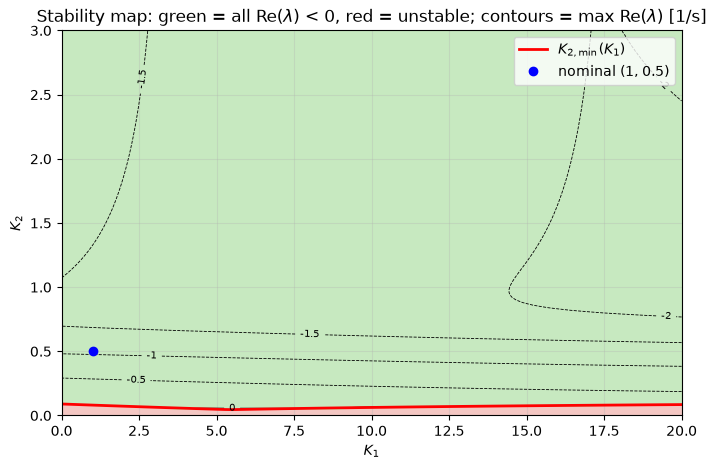

In [30]:
# Threshold K2_min(K1): below it the nozzle restoring action cannot beat the aerodynamic stiffness mu.
# a0 = 0 means a pole at the origin (static torque balance lost) -> analytic candidate for the threshold.
K2_a0 = sp.solve(sp.Eq(a0, 0), K2s)[0]
display(Math(rf"a_0 > 0 \;\Longleftrightarrow\; K_2 > {sp.latex(sp.N(K2_a0, 5))}"))
f_K2a0 = sp.lambdify(K1s, K2_a0, "numpy")

print(" K1 | K2_min (numeric) | K2 from a0=0")
for k1 in (0.5, 1, 2, 5, 10, 20):
    print(f"{k1:4g} | {k2_min(k1):16.4f} | {float(f_K2a0(k1)):.4f}")

K1_f, K2_f = np.linspace(0, 20, 201), np.linspace(0, 3, 151)
mre_f = stability_grid(K1_f, K2_f)
k1_line = np.linspace(0, 20, 81)

fig, ax = plt.subplots(figsize=(8, 5))
ax.contourf(K1_f, K2_f, mre_f < 0, levels=[-0.5, 0.5, 1.5], colors=["#f4c7c3", "#c7e9c0"])
cs = ax.contour(K1_f, K2_f, mre_f, levels=[-4, -3, -2, -1.5, -1, -0.5, 0], colors="k", linewidths=0.6)
ax.clabel(cs, fmt="%g", fontsize=7)
ax.plot(k1_line, [k2_min(k) for k in k1_line], "r-", lw=2, label=r"$K_{2,\min}(K_1)$")
ax.plot([1], [0.5], "bo", label="nominal (1, 0.5)")
ax.set_xlabel("$K_1$"); ax.set_ylabel("$K_2$")
ax.set_title("Stability map: green = all Re($\\lambda$) < 0, red = unstable; contours = max Re($\\lambda$) [1/s]")
ax.legend(loc="upper right"); ax.grid(alpha=0.3)
save_fig("fig_stab_map"); plt.show()

**Case K2 = 0 (steering channel off)**

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

K2 = 0: unstable pole = +0.5569 1/s, theta(3.5 s) = 19.7 deg, delta(3.5 s) = 0.00 deg


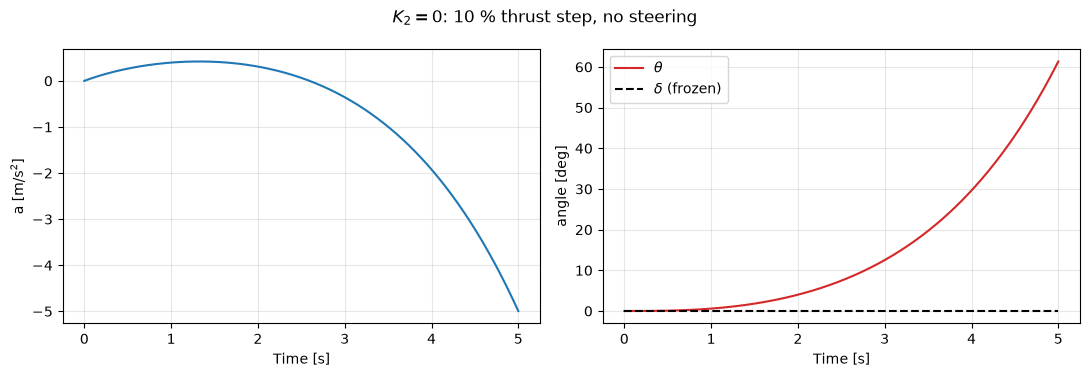

In [31]:
A0, B0, C0, D0 = build_system(1.0, 0.0)
sys0, A0n, B0n, C0n, D0n, *_ = define_mimo_system(A0, B0, C0, D0, show=False)
r0 = check_system_properties(A0n, B0n, C0n)

# A 10 % thrust step (u1) with no steering: theta is only excited by the misalignment moment k_eps*a
T0 = np.linspace(0, 5, 1000)
_, y0, x0 = signal.lsim(sys0, np.column_stack([10 * np.ones_like(T0), np.zeros_like(T0)]), T0)
i35 = np.argmin(np.abs(T0 - 3.5))
print(f"K2 = 0: unstable pole = {np.max(r0['poles'].real):+.4f} 1/s, "
      f"theta(3.5 s) = {np.degrees(y0[i35, 1]):.1f} deg, delta(3.5 s) = {np.degrees(x0[i35, 3]):.2f} deg")

fig, axs = plt.subplots(1, 2, figsize=(11, 3.8))
axs[0].plot(T0, y0[:, 0], color="tab:blue"); axs[0].set_ylabel("a [m/s$^2$]")
axs[1].plot(T0, np.degrees(y0[:, 1]), color="tab:red", label=r"$\theta$")
axs[1].plot(T0, np.degrees(x0[:, 3]), color="k", ls="--", label=r"$\delta$ (frozen)")
axs[1].set_ylabel("angle [deg]"); axs[1].legend()
for ax in axs: ax.set_xlabel("Time [s]"); ax.grid(alpha=0.3)
fig.suptitle("$K_2=0$: 10 % thrust step, no steering"); plt.tight_layout()
save_fig("fig_k2_0_unstable"); plt.show()

### B7. Response to test inputs

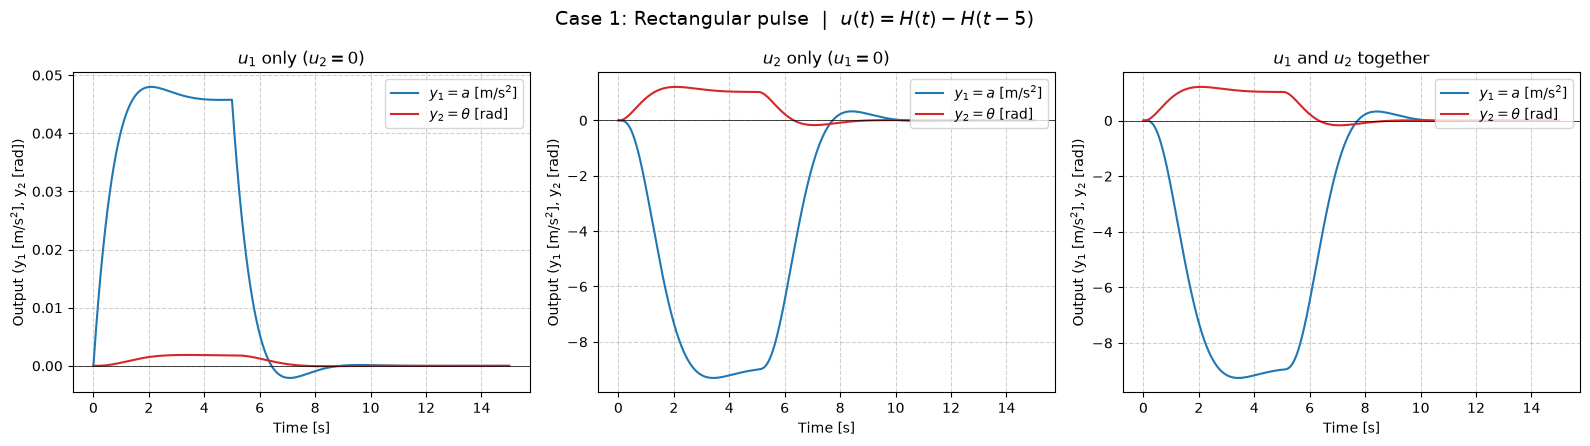

In [32]:
# Case 1: rectangular pulse u(t) = H(t) - H(t-5)  (unit input switched on at t=0 and off at t=5 s)
def u_pulse(t):
    # Heaviside step H(t) minus the same step delayed 5 s
    return np.heaviside(t, 1.0) - np.heaviside(t - 5.0, 1.0)

# Simulate 15 s so the response after the pulse ends (t > 5 s) is also visible
T1, y_pulse = simulate_input_cases(sys, u_pulse, T_max=15,
                                   title="Case 1: Rectangular pulse",
                                   save_as="fig_q7_pulse", u_label=r"$u(t)=H(t)-H(t-5)$")

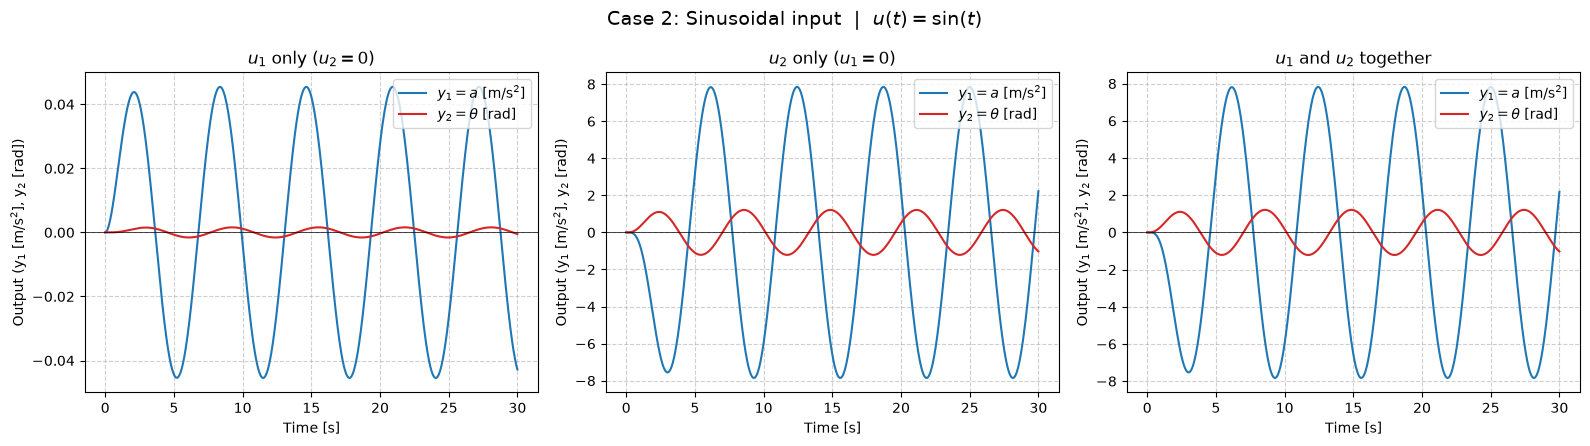

In [33]:
# Case 2: sinusoidal input u(t) = sin(t)  (omega = 1 rad/s)
def u_sine(t):
    return np.sin(t)

# Simulate 30 s (about 5 periods) so the transient dies out and the steady-state oscillation shows
T2, y_sine = simulate_input_cases(sys, u_sine, T_max=30,
                                  title="Case 2: Sinusoidal input",
                                  save_as="fig_q7_sine", u_label=r"$u(t)=\sin(t)$")

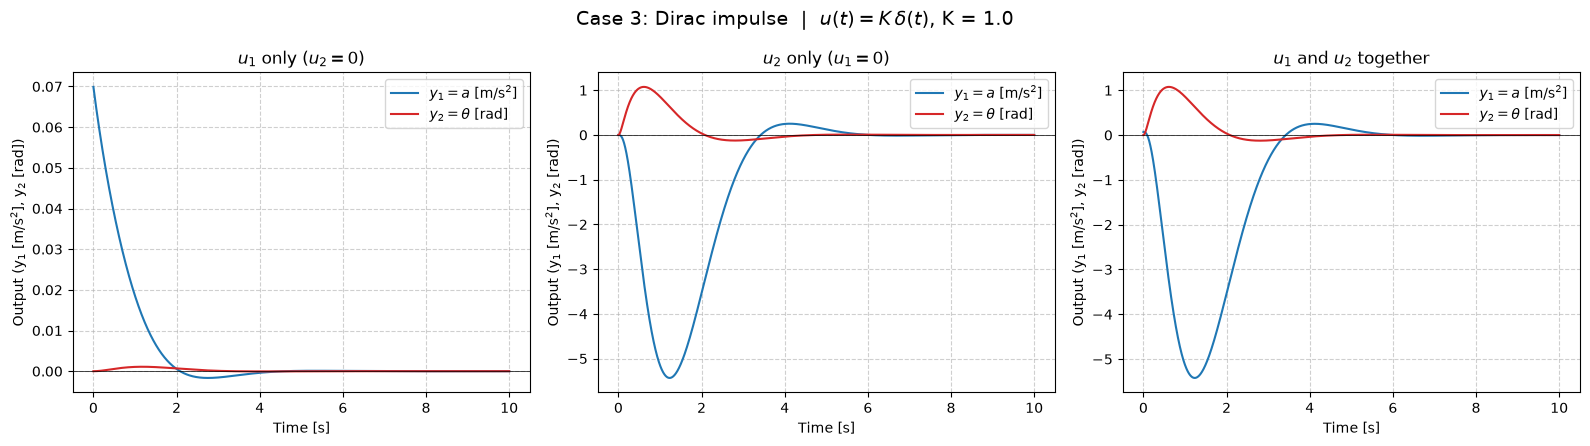

In [34]:
# Case 3: Dirac impulse u(t) = K * delta(t)  (wind gust / sudden hit)
K_impulse = 1.0   # impulse strength K (change to scale the gust)

# Impulse response is computed with signal.impulse inside the helper (impulse_K activates that branch)
# 10 s is enough to see the response decay back to zero (all poles are in the left half-plane)
T3, y_impulse = simulate_input_cases(sys, None, T_max=10,
                                     title="Case 3: Dirac impulse",
                                     save_as="fig_q7_impulse", u_label=r"$u(t)=K\,\delta(t)$, K = " + str(K_impulse),
                                     impulse_K=K_impulse)

### B8. Cross-coupling in percent

Gains used in this section: **$K_1 = 1$, $K_2 = 0.5$** (nominal, the values stored in `K1`, `K2`). Test steps: $u_1 = 10\,\%$ and $u_2 = 5^\circ$.

How each percentage follows from the gains (through the DC gain matrix $G(0)$ computed with those gains):

| Quantity | Formula | Value at $(1,\,0.5)$ |
|---|---|---|
| main $a$ (from $u_1$) | $G_{11}(0)\cdot 10$ | $0.0459\cdot 10 = 0.459$ m/s² |
| coupled $a$ (from $u_2$) | $G_{12}(0)\cdot 5^\circ$ | $-8.975\cdot 0.0873 = -0.783$ m/s² |
| main $\theta$ (from $u_2$) | $G_{22}(0)\cdot 5^\circ$ | $1.0403\cdot 5^\circ = 5.20^\circ$ |
| coupled $\theta$ (from $u_1$) | $G_{21}(0)\cdot 10$ | $0.0018\cdot 10 = 0.018$ rad $= 1.03^\circ$ |

The percentages use the *peak* of the coupled output (0.812 m/s², 1.07°), a bit above these final values: $0.812/0.459 = 176.9\,\%$ and $1.07/5.20 = 20.6\,\%$. The gains enter through the denominators: a larger $K_1$ raises $G_{11}(0)$ (bigger main $a$, so a smaller $u_2\to a$ percentage); $K_2$ sets $G_{22}(0)$ and how much the nozzle holds the pitch. The last table of the cell below repeats the computation for other gain pairs.

**Note on the step sizes.** We applied steps of $u_1 = 10\,\%$ and $u_2 = 5^\circ$; the project statement does not set their size. The two coupling percentages depend on the ratio $u_2/u_1$, so they are reported for this pair of steps.

K1 = 1.0, K2 = 0.5
u2 = 5 deg   : theta_final = 5.20 deg (main),   peak |a| = 0.812 m/s^2 (coupled)
u1 = 10 %    : a_final = 0.459 m/s^2 (main),   peak |theta| = 1.07 deg (coupled)
u2 -> a     coupling = 176.9 %  (peak coupled a vs. a produced by u1)
u1 -> theta coupling = 20.6 %  (peak coupled theta vs. theta produced by u2)
DC gain matrix G(0) (unit steps; rows a, theta; columns u1, u2) =
 [[ 4.5900e-02 -8.9751e+00]
 [ 1.8000e-03  1.0403e+00]]
Check with G(0): main a = 0.459, coupled a = -0.783 m/s^2, main theta = 5.20 deg, coupled theta = 1.03 deg

   K1    K2 | G11(0)  G12(0)  G21(0)  G22(0) | a_main  th_main | u2->a [%]  u1->theta [%]
    1   0.5 |  0.046  -8.975  0.0018   1.040 |  0.459    5.20  |     176.9         20.6
   10   0.5 |  0.325  -6.352  0.0128   1.144 |  3.248    5.72  |      17.7        132.5
    1   1.3 |  0.056  -8.758  0.0007   1.015 |  0.556    5.08  |     137.4          7.6
  4.5   1.3 |  0.210  -7.331  0.0026   1.033 |  2.095    5.16  |      30.5         28.3


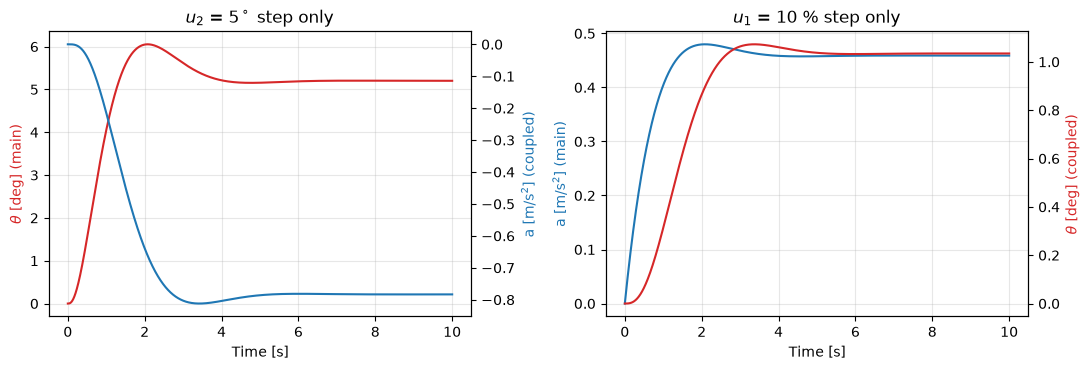

In [35]:
# Test steps used in this work: u1 = 10 % thrust, u2 = 5 deg of pitch command (size not set by the statement)
cm = coupling_metrics(K1, K2)
print(f"K1 = {K1}, K2 = {K2}")
print(f"u2 = 5 deg   : theta_final = {np.degrees(cm['th_main']):.2f} deg (main),   peak |a| = {cm['a_dev']:.3f} m/s^2 (coupled)")
print(f"u1 = 10 %    : a_final = {cm['a_main']:.3f} m/s^2 (main),   peak |theta| = {np.degrees(cm['th_dev']):.2f} deg (coupled)")
print(f"u2 -> a     coupling = {cm['pct_u2_to_a']:.1f} %  (peak coupled a vs. a produced by u1)")
print(f"u1 -> theta coupling = {cm['pct_u1_to_theta']:.1f} %  (peak coupled theta vs. theta produced by u2)")
print("DC gain matrix G(0) (unit steps; rows a, theta; columns u1, u2) =\n", np.round(cm['G0'], 4))
G0 = cm['G0']
print(f"Check with G(0): main a = {G0[0,0]*10:.3f}, coupled a = {G0[0,1]*np.radians(5):.3f} m/s^2, "
      f"main theta = {np.degrees(G0[1,1]*np.radians(5)):.2f} deg, coupled theta = {np.degrees(G0[1,0]*10):.2f} deg")

# Same percentages for other gain pairs (what each gain does to the coupling)
print(f"\n{'K1':>5} {'K2':>5} | G11(0)  G12(0)  G21(0)  G22(0) | a_main  th_main | u2->a [%]  u1->theta [%]")
for k1_, k2_ in [(1, 0.5), (10, 0.5), (1, 1.3), (4.5, 1.3)]:
    c = coupling_metrics(k1_, k2_); g = c['G0']
    print(f"{k1_:5g} {k2_:5g} | {g[0,0]:6.3f} {g[0,1]:7.3f} {g[1,0]:7.4f} {g[1,1]:7.3f} | {c['a_main']:6.3f} {np.degrees(c['th_main']):7.2f}  | {c['pct_u2_to_a']:9.1f} {c['pct_u1_to_theta']:12.1f}")

fig, axs = plt.subplots(1, 2, figsize=(11, 3.8))
axs[0].plot(cm['T'], np.degrees(cm['y_u2'][:, 1]), "tab:red")
axs0b = axs[0].twinx(); axs0b.plot(cm['T'], cm['y_u2'][:, 0], "tab:blue")
axs[0].set_title("$u_2$ = 5$^\\circ$ step only"); axs[0].set_ylabel(r"$\theta$ [deg] (main)", color="tab:red"); axs0b.set_ylabel("a [m/s$^2$] (coupled)", color="tab:blue")
axs[1].plot(cm['T'], cm['y_u1'][:, 0], "tab:blue")
axs1b = axs[1].twinx(); axs1b.plot(cm['T'], np.degrees(cm['y_u1'][:, 1]), "tab:red")
axs[1].set_title("$u_1$ = 10 % step only"); axs[1].set_ylabel("a [m/s$^2$] (main)", color="tab:blue"); axs1b.set_ylabel(r"$\theta$ [deg] (coupled)", color="tab:red")
for ax in axs: ax.set_xlabel("Time [s]"); ax.grid(alpha=0.3)
plt.tight_layout(); save_fig("fig_coupling"); plt.show()

**B7: effect of K1 and K2 on speed and stability** (steps u2 = 5 deg and u1 = 10 %)

   K1    K2 | Mp_th[%] ts_th[s] | Mp_a[%] ts_a[s] | ess[%] dmax[deg] | G11(0)
    1   0.1 |     88.0    10.00 |     nan   10.00 |  24.04      1.79 | -0.0314
    1  0.25 |     38.5     9.73 |    54.1    8.80 |   8.40      1.40 | 0.0290
    1   0.5 |     16.4     3.64 |     4.6    3.00 |   4.03      2.01 | 0.0459
    1     1 |      3.6     2.98 |     0.0    2.42 |   1.98      3.64 | 0.0538
    1     2 |      0.6     1.75 |     0.0    2.97 |   0.98      6.37 | 0.0577
  0.5  1.25 |      2.1     2.55 |     0.0    2.73 |   1.26      4.38 | 0.0285
    1  1.25 |      1.9     1.47 |     0.0    2.65 |   1.57      4.37 | 0.0554
    5  1.25 |      0.8     1.61 |     0.0    2.15 |   3.60      4.35 | 0.2267
   10  1.25 |      0.2     1.76 |     0.1    1.74 |   5.29      4.32 | 0.3696
   20  1.25 |      0.0     1.94 |     0.2    1.27 |   7.30      5.63 | 0.5398


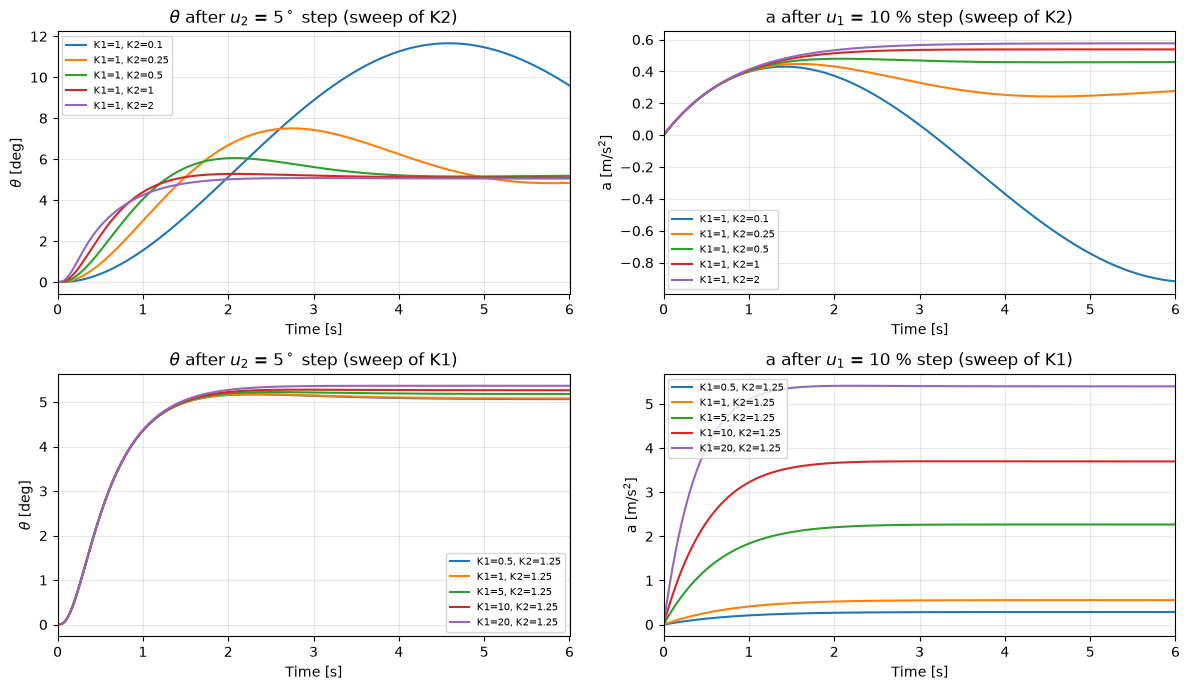

In [36]:
fig, axs = plt.subplots(2, 2, figsize=(12, 7))
sweeps = [("K2", [(1.0, k2) for k2 in (0.1, 0.25, 0.5, 1.0, 2.0)]), ("K1", [(k1, 1.25) for k1 in (0.5, 1.0, 5.0, 10.0, 20.0)])]
print(f"{'K1':>5} {'K2':>5} | Mp_th[%] ts_th[s] | Mp_a[%] ts_a[s] | ess[%] dmax[deg] | G11(0)")
for row, (name, pairs) in enumerate(sweeps):
    for k1, k2 in pairs:
        m = gain_metrics(k1, k2, traces=True)
        lab = f"K1={k1:g}, K2={k2:g}"
        if m is None:
            print(f"{k1:5g} {k2:5g} | UNSTABLE"); continue
        axs[row, 0].plot(m["T"], np.degrees(m["X2"][:, 1]), label=lab)
        axs[row, 1].plot(m["T"], m["X1"][:, 0], label=lab)
        print(f"{k1:5g} {k2:5g} | {m['Mp_th']:8.1f} {m['ts_th']:8.2f} | {m['Mp_a']:7.1f} {m['ts_a']:7.2f} | {m['ess']:6.2f} {m['dmax']:9.2f} | {m['g11']:.4f}")
    axs[row, 0].set_title(rf"$\theta$ after $u_2$ = 5$^\circ$ step (sweep of {name})"); axs[row, 0].set_ylabel(r"$\theta$ [deg]")
    axs[row, 1].set_title(f"a after $u_1$ = 10 % step (sweep of {name})"); axs[row, 1].set_ylabel("a [m/s$^2$]")
    for a in axs[row]: a.set_xlim(0, 6); a.grid(alpha=0.3); a.legend(fontsize=7); a.set_xlabel("Time [s]")
plt.tight_layout(); save_fig("fig_q7_gain_sweep"); plt.show()

## C. Frequency response

### C9. Poles, zeros and Bode diagrams

The Bode diagram plots, for each channel, the gain (in dB) and the phase lag of the output when the input is a sinusoid of frequency $\omega$. The final slope of the magnitude is $-20\,r$ dB per decade, where $r$ = (number of poles) $-$ (number of zeros) is the **relative degree**: each pole not matched by a zero is one more dynamic link (integrator or lag) between input and output, and every link attenuates 20 dB per decade and adds $-90^\circ$ of phase at high frequency. The cell below measures those slopes numerically.

Pole                 |  participation in:  a    theta  omega  delta
  -1.066 +1.199j   |                0.17   0.46   0.33   0.04
  -1.066 -1.199j   |                0.17   0.46   0.33   0.04
  -2.092 +0.000j   |                0.28   0.24   0.46   0.01
 -17.264 +0.000j   |                0.00   0.01   0.14   0.85

Zeros of each channel (K1=1, K2=0.5):
  G11: zeros = [-17.265+0.j     -1.543+1.074j  -1.543-1.074j]
  G12: zeros = none
  G21: zeros = [-20.]
  G22: zeros = [-1.137]


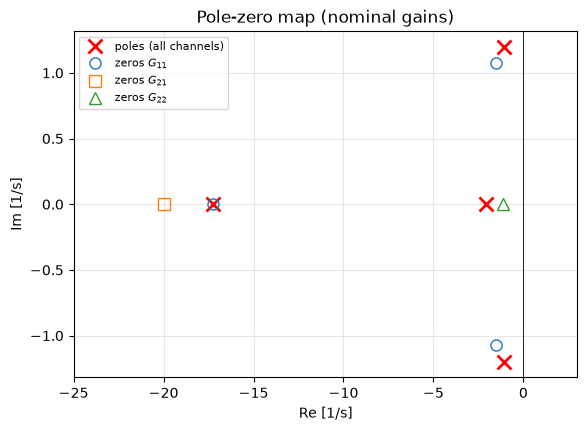


Final Bode slope of each channel (poles = 4, zeros from A4.2):
channel zeros  r = poles - zeros  expected slope [dB/dec]  measured 100->1000 rad/s  
G11     3      1                  -20                      -20.0                     
G12     0      4                  -80                      -79.9                     
G21     1      3                  -60                      -60.0                     
G22     1      3                  -60                      -59.9                     


In [37]:
# Poles, modal participation (which state each pole acts on) and zeros of every channel
poles, P = pole_participation(A_num)
names = ["a", "theta", "omega", "delta"]
print("Pole                 |  participation in:  a    theta  omega  delta")
for lam_k, row in zip(poles, P):
    print(f"{lam_k.real:8.3f} {lam_k.imag:+.3f}j   |               " + "  ".join(f"{v:5.2f}" for v in row))

print("\nZeros of each channel (K1=%g, K2=%g):" % (K1, K2))
for i in range(2):
    for j in range(2):
        num, den = signal.ss2tf(A_num, B_num[:, [j]], C_num[[i], :], D_num[[i], [j]])
        z = np.roots(np.trim_zeros(np.round(num[0], 10), 'f'))
        print(f"  G{i+1}{j+1}: zeros = {np.round(z, 3) if len(z) else 'none'}")

fig, ax = plt.subplots(figsize=(6.5, 4.5))
ax.plot(poles.real, poles.imag, "rx", ms=10, mew=2, label="poles (all channels)")
mk_ = {(1, 1): "o", (2, 1): "s", (2, 2): "^"}
for (i, j), m in mk_.items():
    num, _ = signal.ss2tf(A_num, B_num[:, [j - 1]], C_num[[i - 1], :], D_num[[i - 1], [j - 1]])
    z = np.roots(np.trim_zeros(np.round(num[0], 10), 'f'))
    ax.plot(z.real, z.imag, m, mfc="none", ms=8, label=f"zeros $G_{{{i}{j}}}$")
ax.axvline(0, color="k", lw=0.6); ax.set_xlabel("Re [1/s]"); ax.set_ylabel("Im [1/s]")
ax.set_xlim(-25, 3); ax.grid(alpha=0.3); ax.legend(fontsize=8); ax.set_title("Pole-zero map (nominal gains)")
save_fig("fig_polezero"); plt.show()

# Why the Bode magnitudes fall with the slopes seen in the figure below:
# at high frequency G_ij ~ k / p^r, with r = (number of poles) - (number of zeros) = relative degree,
# so the magnitude drops 20*r dB per decade and the phase tends to -90*r deg (+ the sign of k).
print("\nFinal Bode slope of each channel (poles = 4, zeros from A4.2):")
print(f"{'channel':<8}{'zeros':<7}{'r = poles - zeros':<19}{'expected slope [dB/dec]':<25}{'measured 100->1000 rad/s':<26}")
mag = lambda name, w: abs(np.polyval(TF[name]["num"], 1j*w) / np.polyval(den_c, 1j*w))
for name in ("G11", "G12", "G21", "G22"):
    r = 4 - len(TF[name]["zeros"])
    meas = 20 * np.log10(mag(name, 1e3) / mag(name, 1e2))
    print(f"{name:<8}{len(TF[name]['zeros']):<7}{r:<19}{-20*r:<25}{meas:<26.1f}")


/private/tmp/claude-501/-Users-josebarreno-Documents-TSII-TSII-Cohete-proyect/40b561e5-c1fd-435d-ae96-7a7942786e17/scratchpad/venv/lib/python3.13/site-packages/scipy/signal/_filter_design.py:1234: BadCoefficients: Badly conditioned filter coefficients (numerator): the results may be meaningless
  b, a = normalize(b, a)


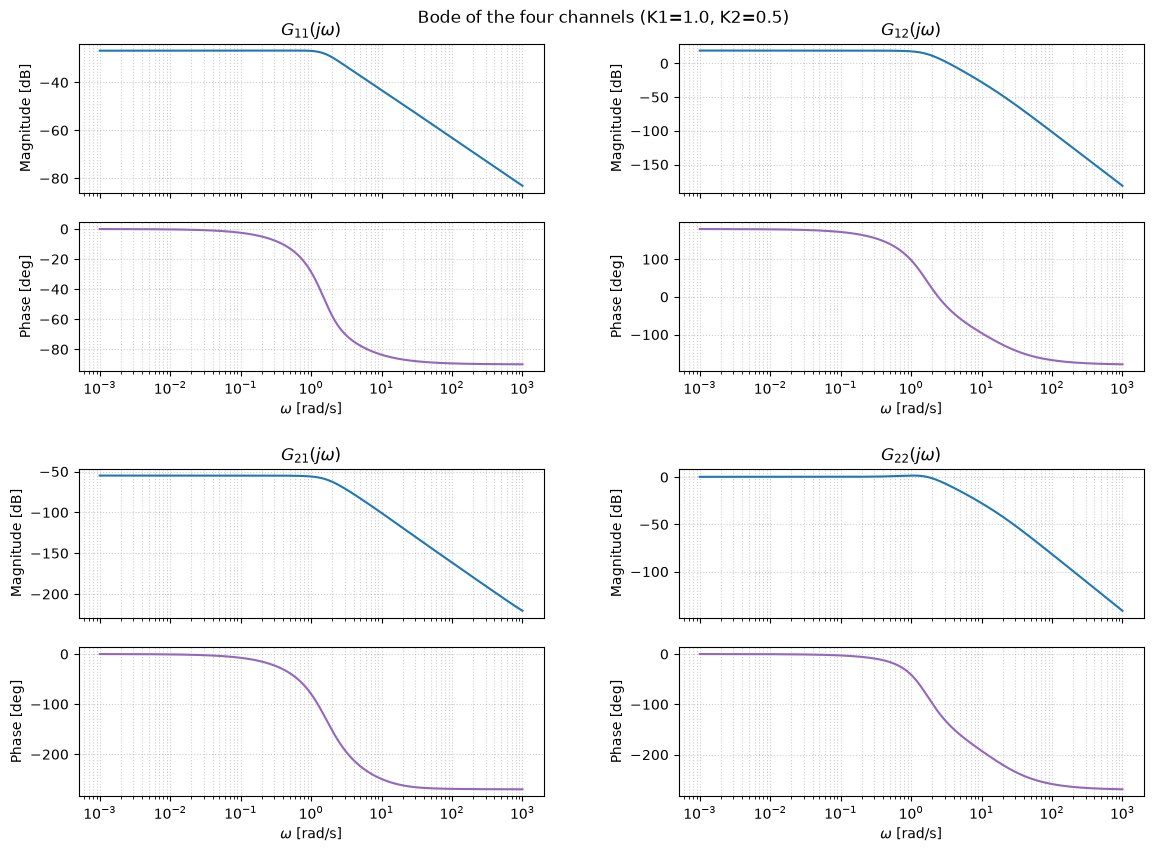

In [38]:
fig = plot_bode_2x2(A_num, B_num, C_num, D_num, title=f"Bode of the four channels (K1={K1}, K2={K2})")
fig.savefig("imgs/fig_bode_2x2.png", dpi=200, bbox_inches="tight"); plt.show()

### C10. Bandwidth, resonance peak and frequency range of the coupling

   K2 | G11: DC      BW[rad/s]  Mr  | G22: DC      BW[rad/s]  Mr  | G12: DC      BW[rad/s]  Mr  | G21: DC      BW[rad/s]  Mr 
 0.25 |    0.0290     3.299  2.15 |    1.0840     1.765  1.70 |    9.3522     1.420  1.31 |    0.0038     1.420  1.31
  0.5 |    0.0459     2.062  1.01 |    1.0403     2.264  1.17 |    8.9751     1.386  1.00 |    0.0018     1.391  1.00
    1 |    0.0538     1.480  1.00 |    1.0198     2.351  1.01 |    8.7977     1.088  1.00 |    0.0009     1.092  1.00
 1.25 |    0.0554     1.391  1.00 |    1.0157     2.264  1.00 |    8.7631     1.033  1.00 |    0.0007     1.037  1.00
    2 |    0.0577     1.280  1.00 |    1.0098     2.055  1.00 |    8.7116     0.961  1.00 |    0.0004     0.964  1.00
    3 |    0.0590     1.228  1.00 |    1.0065     1.925  1.00 |    8.6833     0.925  1.00 |    0.0003     0.928  1.00


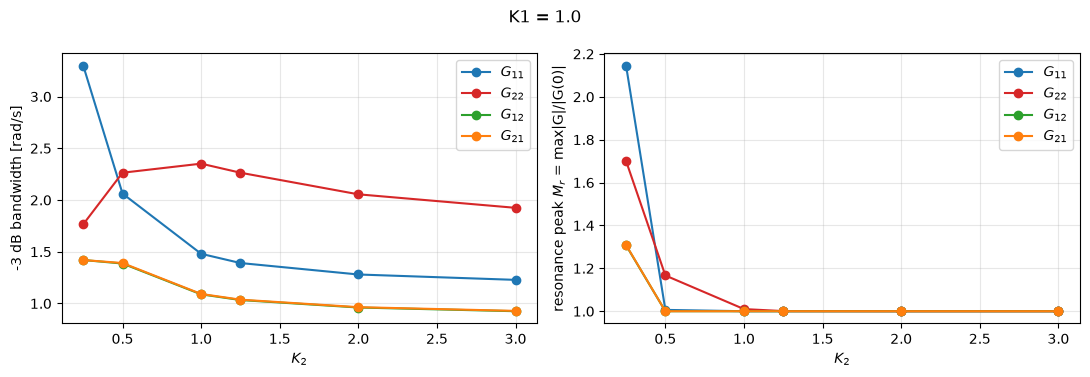

In [39]:
# Bandwidth (-3 dB) and resonance peak of each channel as K2 grows (K1 fixed)
K2_list = [0.25, 0.5, 1.0, 1.25, 2.0, 3.0]
rows = {}
print("   K2 | " + " | ".join(f"G{i}{j}: DC      BW[rad/s]  Mr " for i, j in [(1,1),(2,2),(1,2),(2,1)]))
for k2 in K2_list:
    Ak, Bk, Ck, Dk = (np.array(M) for M in build_system(K1, k2))
    m = channel_freq_metrics(Ak, Bk, Ck, Dk); rows[k2] = m
    print(f"{k2:5g} | " + " | ".join(f"{m[c]['dc']:9.4f} {m[c]['bw']:9.3f} {m[c]['mr']:5.2f}" for c in [(1,1),(2,2),(1,2),(2,1)]))

fig, axs = plt.subplots(1, 2, figsize=(11, 3.8))
for c, col in [((1, 1), "tab:blue"), ((2, 2), "tab:red"), ((1, 2), "tab:green"), ((2, 1), "tab:orange")]:
    axs[0].plot(K2_list, [rows[k][c]["bw"] for k in K2_list], "o-", color=col, label=f"$G_{{{c[0]}{c[1]}}}$")
    axs[1].plot(K2_list, [rows[k][c]["mr"] for k in K2_list], "o-", color=col, label=f"$G_{{{c[0]}{c[1]}}}$")
axs[0].set_ylabel("-3 dB bandwidth [rad/s]"); axs[1].set_ylabel("resonance peak $M_r$ = max|G|/|G(0)|")
for a in axs: a.set_xlabel("$K_2$"); a.grid(alpha=0.3); a.legend()
fig.suptitle(f"K1 = {K1}"); plt.tight_layout(); save_fig("fig_bw_vs_k2"); plt.show()

K1=1, K2=0.5: coupling >= 10 % up to  w = 7.35 rad/s (u2->a),  1.96 rad/s (u1->theta);  DC: 170.7 % and 19.9 %
K1=5, K2=1.25: coupling >= 10 % up to  w = 4.23 rad/s (u2->a),  4.41 rad/s (u1->theta);  DC: 27.6 % and 31.9 %


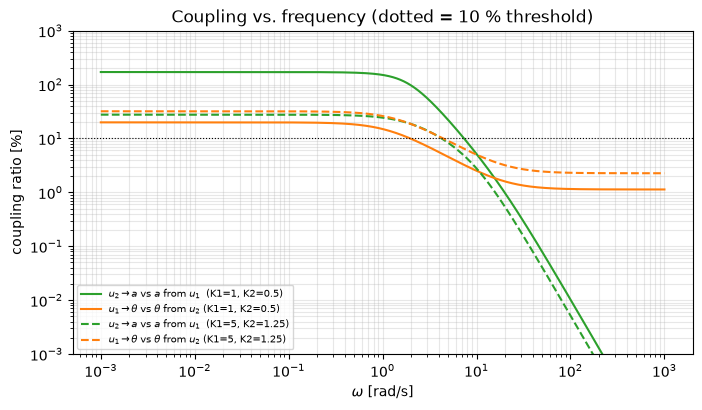

In [40]:
# Where is the coupling significant?  Ratios scaled with the step sizes of B8 (u1 = 10 %, u2 = 5 deg)
U1, U2, THR = 10.0, np.radians(5.0), 0.10
w = W_DEFAULT

def coupling_ratios(K1_, K2_):
    A_, B_, C_, D_ = (np.array(M) for M in build_system(K1_, K2_))
    m = channel_freq_metrics(A_, B_, C_, D_, w)
    r12 = (m[(1, 2)]["mag"] * U2) / (m[(1, 1)]["mag"] * U1)    # u2 -> a   relative to a produced by u1
    r21 = (m[(2, 1)]["mag"] * U1) / (m[(2, 2)]["mag"] * U2)    # u1 -> theta relative to theta produced by u2
    return r12, r21

def above_threshold_until(r):
    """Highest frequency at which the ratio is still >= THR (above it the channel can be treated as independent)."""
    idx = np.where(r >= THR)[0]
    return float(w[idx[-1]]) if len(idx) else 0.0

fig, ax = plt.subplots(figsize=(8, 4.2))
for (k1_, k2_), ls in [((1.0, 0.5), "-"), ((5.0, 1.25), "--")]:
    r12, r21 = coupling_ratios(k1_, k2_)
    ax.loglog(w, r12 * 100, "tab:green", ls=ls, label=rf"$u_2\to a$ vs $a$ from $u_1$  (K1={k1_:g}, K2={k2_:g})")
    ax.loglog(w, r21 * 100, "tab:orange", ls=ls, label=rf"$u_1\to\theta$ vs $\theta$ from $u_2$ (K1={k1_:g}, K2={k2_:g})")
    print(f"K1={k1_:g}, K2={k2_:g}: coupling >= {THR*100:.0f} % up to  w = {above_threshold_until(r12):.2f} rad/s (u2->a),  "
          f"{above_threshold_until(r21):.2f} rad/s (u1->theta);  DC: {r12[0]*100:.1f} % and {r21[0]*100:.1f} %")
ax.axhline(THR * 100, color="k", lw=0.8, ls=":"); ax.set_xlabel(r"$\omega$ [rad/s]"); ax.set_ylabel("coupling ratio [%]")
ax.set_ylim(1e-3, 1e3); ax.grid(True, which="both", alpha=0.3); ax.legend(fontsize=7, loc="lower left")
ax.set_title("Coupling vs. frequency (dotted = 10 % threshold)")
save_fig("fig_coupling_ratio"); plt.show()

## D. Observability and controllability

### D11. Observability

In [41]:
# Rank and sigma_min of O = [C; CA; CA^2; CA^3] for each sensor set, plus counter-cases without the coupling terms
OBS_CASES = [("a and theta",                C_BOTH,  {}),
             ("a only",                     C_ACCEL, {}),
             ("theta only",                 C_PITCH, {}),
             ("a, theta and omega",         C_WITH_OMEGA, {}),
             ("a only, c_theta = 0",        C_ACCEL, dict(c_theta=0.0)),
             ("theta only, k_eps = 0",      C_PITCH, dict(k_eps=0.0))]
print(f"{'Sensors':26s} | rank O | sigma_min(O)")
obs_table = {}
for name, Cs, ov in OBS_CASES:
    A_, B_, C_, D_ = (np.array(M) for M in build_system(K1, K2, C=Cs, **ov))
    r = check_system_properties(A_, B_, C_, show=False)
    obs_table[name] = r
    print(f"{name:26s} |   {r['rank_obs']}    | {r['sigma_min_obs']:.4g}")

Sensors                    | rank O | sigma_min(O)
a and theta                |   4    | 1.172
a only                     |   4    | 0.9933
theta only                 |   4    | 0.02611
a, theta and omega         |   4    | 1.34
a only, c_theta = 0        |   1    | 0
theta only, k_eps = 0      |   3    | 0


**Reconstructing omega and delta without measuring them** (Luenberger observer, free response)

a only    : |error| at t = 3 s -> omega 9.03e-10, delta 6.90e-10; peak |L| = 22.5
theta only: |error| at t = 3 s -> omega 1.41e-10, delta 2.93e-11; peak |L| = 3.74e+03


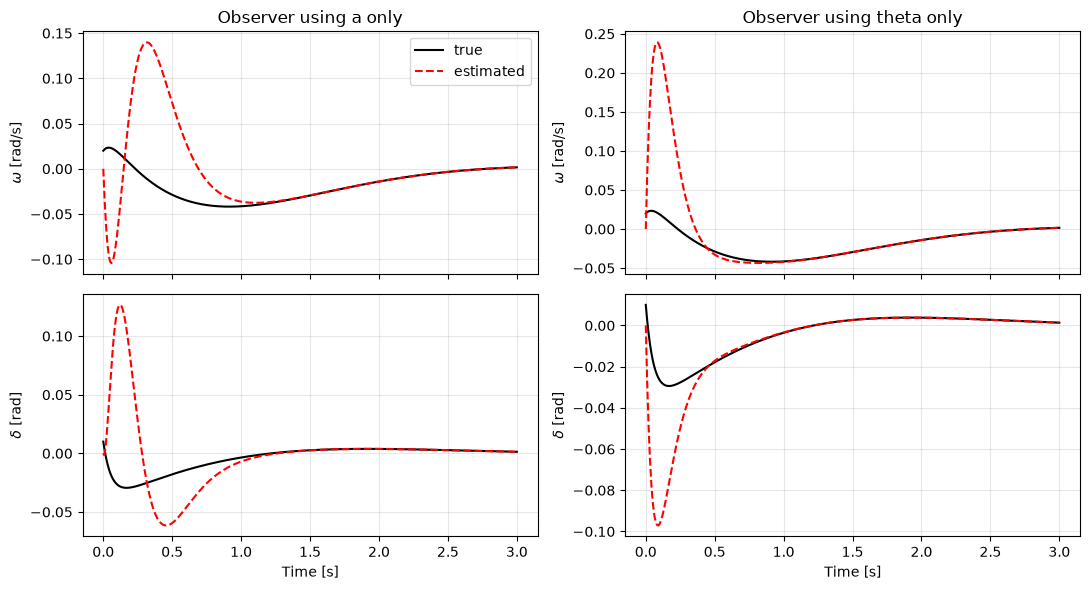

In [42]:
# Observer  xhat' = A xhat + L (y - C xhat),  poles placed at -8, -10, -12, -14 (faster than the plant dynamics)
OBS_POLES = [-8.0, -10.0, -12.0, -14.0]
x0 = np.array([0.5, 0.05, 0.02, 0.01])          # true initial state; the observer starts from zero
Tg = np.linspace(0, 3, 600)
fig, axs = plt.subplots(2, 2, figsize=(11, 6), sharex=True)
for col, (name, Cs) in enumerate([("a only", C_ACCEL), ("theta only", C_PITCH)]):
    A_, B_, C_, D_ = (np.array(M) for M in build_system(K1, K2, C=Cs))
    L = signal.place_poles(A_.T, C_.T, OBS_POLES).gain_matrix.T
    Aaug = np.block([[A_, np.zeros((4, 4))], [L @ C_, A_ - L @ C_]])
    Z = np.array([la.expm(Aaug * t) @ np.concatenate([x0, np.zeros(4)]) for t in Tg])
    for row, (idx, lab) in enumerate([(2, r"$\omega$ [rad/s]"), (3, r"$\delta$ [rad]")]):
        axs[row, col].plot(Tg, Z[:, idx], "k", label="true")
        axs[row, col].plot(Tg, Z[:, 4 + idx], "r--", label="estimated")
        axs[row, col].set_ylabel(lab); axs[row, col].grid(alpha=0.3)
    axs[0, col].set_title(f"Observer using {name}")
    err = np.abs(Z[:, 4:] - Z[:, :4])
    print(f"{name:10s}: |error| at t = 3 s -> omega {err[-1, 2]:.2e}, delta {err[-1, 3]:.2e}; "
          f"peak |L| = {np.max(np.abs(L)):.3g}")
for a in axs[1]: a.set_xlabel("Time [s]")
axs[0, 0].legend(); plt.tight_layout(); save_fig("fig_observer"); plt.show()

### D12. Controllability

In [43]:
# Scenarios: both inputs, only u1 (servo jammed or only thrust), only u2 (thrust control failed), K2 = 0
def jam_servo(A_, B_):
    """Servo stuck: delta' = 0 (row 4 of A and B zero), delta keeps its last value."""
    A2, B2 = A_.copy(), B_.copy(); A2[3, :] = 0; B2[3, :] = 0
    return A2, B2

A_, B_, *_ = (np.array(M) for M in build_system(K1, K2))
A_k0, B_k0, *_ = (np.array(M) for M in build_system(K1, 0.0))
A_j, B_j = jam_servo(A_, B_)
CTRB_CASES = [("u1 and u2 (nominal)",    A_,   B_),
              ("u1 only",                A_,   B_[:, [0]]),
              ("servo jammed (u1 only)", A_j,  B_j[:, [0]]),
              ("u2 only",                A_,   B_[:, [1]]),
              ("K2 = 0",                 A_k0, B_k0)]
ctrb_table = {}
print(f"{'Scenario':24s} | rank | sigma_min | out of reach | stable | max Re(pole)")
for name, Ac, Bc in CTRB_CASES:
    r = controllability_report(Ac, Bc); ctrb_table[name] = r
    print(f"{name:24s} |  {r['rank']}   | {r['sigma_min']:9.4g} | {', '.join(r['unreachable']) or '---':12s} | {str(r['stable']):6s} | {r['max_re']:+.4f}")

ratio = ctrb_table["u1 and u2 (nominal)"]["sigma_min"] / ctrb_table["u1 only"]["sigma_min"]
print(f"\nsigma_min(both) / sigma_min(u1 only) = {ratio:.0f}")
a_u1_tilt = coupling_metrics(K1, K2)["th_dev"]
print(f"10 % thrust (u1 only) tilts the rocket by {np.degrees(coupling_metrics(K1, K2)['y_u1'][-1, 1]):.2f} deg in steady state")

Scenario                 | rank | sigma_min | out of reach | stable | max Re(pole)
u1 and u2 (nominal)      |  4   |       1.3 | ---          | True   | -1.0656
u1 only                  |  4   |  0.001433 | ---          | True   | -1.0656
servo jammed (u1 only)   |  3   |         0 | delta        | False  | +0.5569
u2 only                  |  4   |       1.3 | ---          | True   | -1.0656
K2 = 0                   |  3   |         0 | delta        | False  | +0.5569

sigma_min(both) / sigma_min(u1 only) = 907
10 % thrust (u1 only) tilts the rocket by 1.03 deg in steady state


## E. Gain selection and sampling period

### E13. Recommended range for K1 and K2

**Note on the step sizes.** The sweep uses the same steps as B8 ($u_1 = 10\,\%$, $u_2 = 5^\circ$), and the limit $\delta_{max} \le 5^\circ$ is also referred to those steps. The recommended range below is therefore the one obtained for this pair of steps.

In [44]:
# Grid sweep of the (K1, K2) plane with the criteria below (same steps as B8: u1 = 10 %, u2 = 5 deg)
LIMITS = dict(Mp=10.0, ts=3.0, ess=5.0, dmax=5.0)          # %, s, %, deg
K1_g = np.arange(0.5, 20.01, 0.5)
K2_g = np.arange(0.05, 3.001, 0.05)
M = evaluate_gain_grid(K1_g, K2_g)

with np.errstate(invalid="ignore"):
    passes = dict(Mp=(M["Mp_th"] <= LIMITS["Mp"]) & (M["Mp_a"] <= LIMITS["Mp"]),
                  ts=(M["ts_th"] <= LIMITS["ts"]) & (M["ts_a"] <= LIMITS["ts"]),
                  ess=M["ess"] <= LIMITS["ess"], dmax=M["dmax"] <= LIMITS["dmax"], g11=M["g11"] > 0)
feasible = np.logical_and.reduce(list(passes.values()))
cost = np.fmax(M["c21"], M["c12"])                          # worst of the two couplings [%]
for k, v in passes.items():
    print(f"criterion {k:5s}: {v.sum():5d} of {v.size} grid points pass")
print(f"all criteria: {feasible.sum()} points | K1 in [{K1_g[feasible.any(0)].min():g}, {K1_g[feasible.any(0)].max():g}], "
      f"K2 in [{K2_g[feasible.any(1)].min():g}, {K2_g[feasible.any(1)].max():g}]")

# Recommended zone: feasible AND coupling within 25 % of the best feasible value.
# Recommended point: feasible with a 10 % safety margin on every limit, least coupling.
zone = feasible & (cost <= 1.25 * np.nanmin(np.where(feasible, cost, np.nan)))
with np.errstate(invalid="ignore"):
    margin = ((M["Mp_th"] <= 0.9 * LIMITS["Mp"]) & (M["Mp_a"] <= 0.9 * LIMITS["Mp"]) & (M["ts_th"] <= 0.9 * LIMITS["ts"]) &
              (M["ts_a"] <= 0.9 * LIMITS["ts"]) & (M["ess"] <= 0.9 * LIMITS["ess"]) & (M["dmax"] <= 0.9 * LIMITS["dmax"]) & (M["g11"] > 0))
rr, cc = np.unravel_index(np.nanargmin(np.where(margin, cost, np.nan)), cost.shape)
K1_rec, K2_rec = float(K1_g[cc]), float(K2_g[rr])
zr, zc = np.where(zone)
print(f"recommended zone : K1 in [{K1_g[zc].min():g}, {K1_g[zc].max():g}], K2 in [{K2_g[zr].min():g}, {K2_g[zr].max():g}]")
print(f"recommended point: (K1, K2) = ({K1_rec:g}, {K2_rec:g}); coupling = {M['c21'][rr, cc]:.1f} % (u2->a), {M['c12'][rr, cc]:.1f} % (u1->theta)")
rec = gain_metrics(K1_rec, K2_rec)
print("metrics at the recommended point:", {k: round(float(v), 3) for k, v in rec.items()})
nom = gain_metrics(1.0, 0.5)
print("metrics at the nominal point    :", {k: round(float(v), 3) for k, v in nom.items()})

criterion Mp   :  2039 of 2400 grid points pass
criterion ts   :  1828 of 2400 grid points pass
criterion ess  :  1425 of 2400 grid points pass
criterion dmax :   683 of 2400 grid points pass
criterion g11  :  2320 of 2400 grid points pass
all criteria: 187 points | K1 in [0.5, 12], K2 in [0.85, 1.45]
recommended zone : K1 in [4, 6.5], K2 in [1.1, 1.45]
recommended point: (K1, K2) = (4.5, 1.3); coupling = 30.5 % (u2->a), 28.3 % (u1->theta)
metrics at the recommended point: {'Mp_th': 0.821, 'ts_th': 1.621, 'Mp_a': 0.017, 'ts_a': 2.226, 'ess': 3.252, 'dmax': 4.494, 'g11': 0.21, 'c21': 30.532, 'c12': 28.33}
metrics at the nominal point    : {'Mp_th': 16.386, 'ts_th': 3.642, 'Mp_a': 4.558, 'ts_a': 2.996, 'ess': 4.032, 'dmax': 2.01, 'g11': 0.046, 'c21': 176.901, 'c12': 20.62}


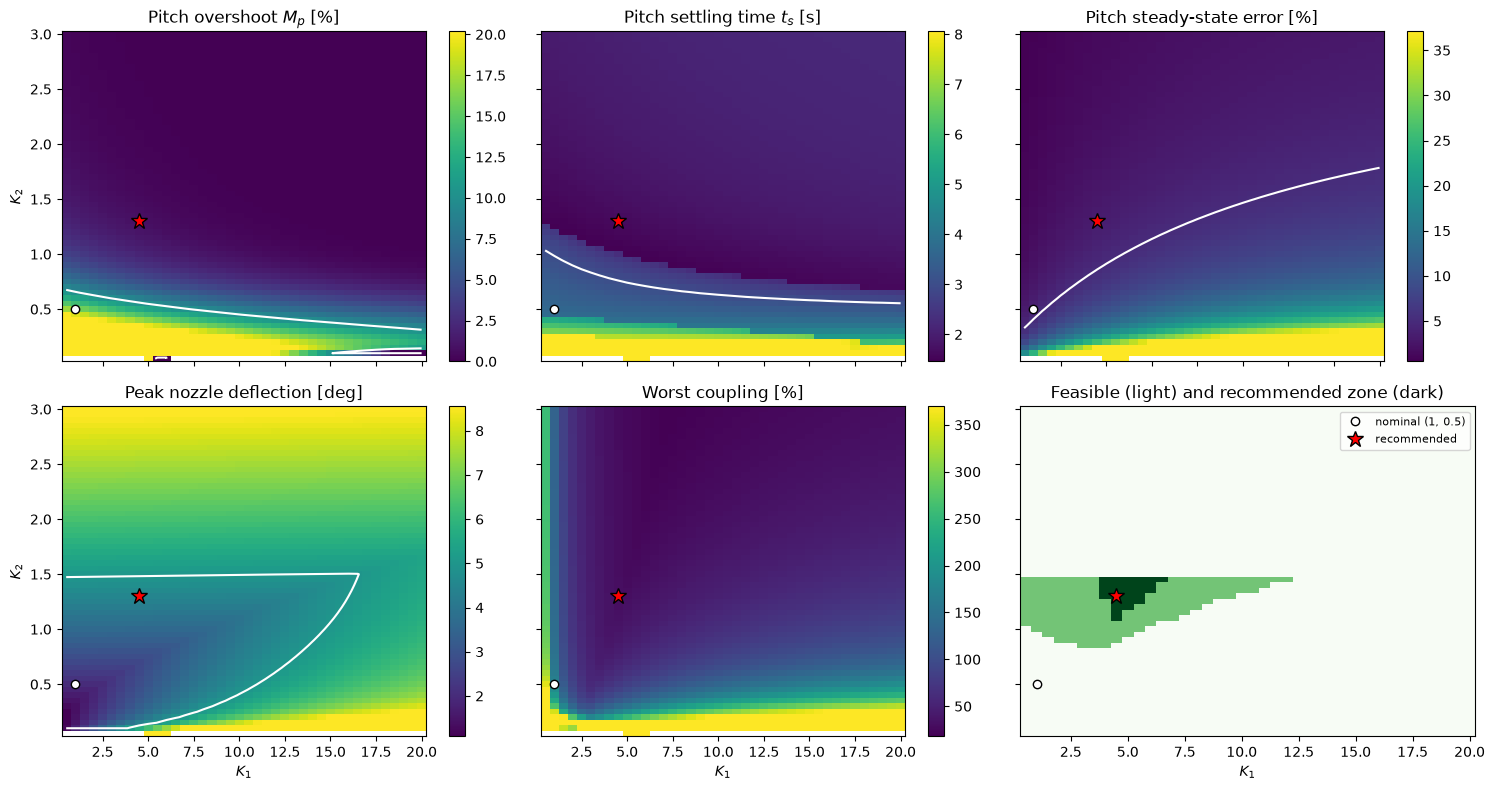

In [45]:
# Maps of every criterion; the contour marks the limit
fig, axs = plt.subplots(2, 3, figsize=(15, 8), sharex=True, sharey=True)
panels = [("Mp_th", "Pitch overshoot $M_p$ [%]", LIMITS["Mp"]), ("ts_th", "Pitch settling time $t_s$ [s]", LIMITS["ts"]),
          ("ess", "Pitch steady-state error [%]", LIMITS["ess"]), ("dmax", "Peak nozzle deflection [deg]", LIMITS["dmax"]),
          ("cost", "Worst coupling [%]", None)]
Z = dict(M, cost=cost)
for ax, (key, title, lim) in zip(axs.flat, panels):
    z = Z[key]
    vmax = np.nanpercentile(z, 95)
    im = ax.pcolormesh(K1_g, K2_g, np.clip(z, 0, vmax), shading="nearest", cmap="viridis")
    fig.colorbar(im, ax=ax)
    if lim is not None:
        ax.contour(K1_g, K2_g, np.nan_to_num(z, nan=1e9), levels=[lim], colors="w", linewidths=1.5)
    ax.set_title(title); ax.plot([1], [0.5], "wo", mec="k"); ax.plot([K1_rec], [K2_rec], "r*", ms=12, mec="k")
ax = axs.flat[5]
ax.pcolormesh(K1_g, K2_g, feasible.astype(float) + zone.astype(float), shading="nearest", cmap="Greens", vmin=0, vmax=2)
ax.plot([1], [0.5], "wo", mec="k", label="nominal (1, 0.5)"); ax.plot([K1_rec], [K2_rec], "r*", ms=12, mec="k", label="recommended")
ax.set_title("Feasible (light) and recommended zone (dark)"); ax.legend(fontsize=8)
for ax in axs[1]: ax.set_xlabel("$K_1$")
for ax in axs[:, 0]: ax.set_ylabel("$K_2$")
plt.tight_layout(); save_fig("fig_metric_maps"); plt.show()

### E-T. Effect of the sampling period T

OK: split model == eqs. (1)-(4); sampled loop -> continuous loop as T -> 0

gains                      | T_max instant [s] | T_max one-sample delay [s] | margin at T=0.05
nominal (1, 0.5)           |             0.999 |                      0.244 | 4.9x (delay case)
recommended (4.5, 1.3)     |             0.427 |                      0.114 | 2.3x (delay case)
high K2 (5, 3)             |             0.239 |                      0.047 | 0.9x (delay case)


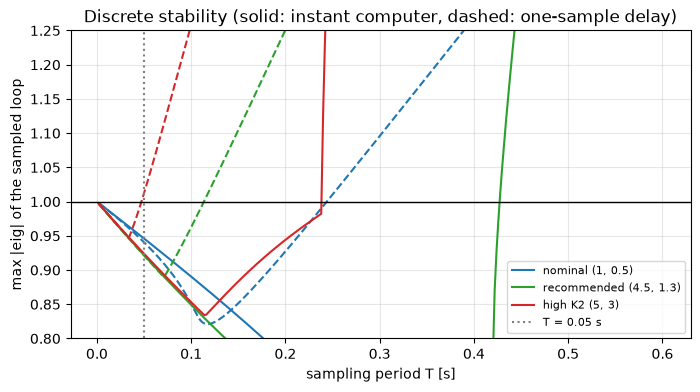

In [46]:
# Check 1: the split plant + controller reproduces the closed-loop matrix A of eqs. (1)-(4)
Ap, Bp, Cy = open_loop_plant()
Kr_, Kf_ = feedback_gain(1.0, 0.5)
assert np.allclose(Ap - Bp @ Kf_ @ Cy, np.array(build_system(1.0, 0.5)[0]))
assert np.allclose(Bp @ Kr_, np.array(build_system(1.0, 0.5)[1]))
# Check 2: T -> 0 recovers the continuous poles
z_small = np.linalg.eigvals(sampled_loop(1.0, 0.5, 1e-5)[0])
assert np.allclose(np.sort(np.log(z_small).real / 1e-5), np.sort(np.linalg.eigvals(A_num).real), rtol=1e-2)
print("OK: split model == eqs. (1)-(4); sampled loop -> continuous loop as T -> 0")

pairs = {"nominal (1, 0.5)": (1.0, 0.5), f"recommended ({K1_rec:g}, {K2_rec:g})": (K1_rec, K2_rec), "high K2 (5, 3)": (5.0, 3.0)}
print(f"\n{'gains':26s} | T_max instant [s] | T_max one-sample delay [s] | margin at T=0.05")
for name, (k1, k2) in pairs.items():
    t0, t1 = t_max(k1, k2), t_max(k1, k2, delay=True)
    print(f"{name:26s} | {t0:17.3f} | {t1:26.3f} | {t1 / T_sample:.1f}x (delay case)")

Ts = np.linspace(0.002, 0.6, 300)
fig, ax = plt.subplots(figsize=(8, 4))
for (name, (k1, k2)), col in zip(pairs.items(), ("tab:blue", "tab:green", "tab:red")):
    ax.plot(Ts, [spectral_radius(k1, k2, t) for t in Ts], color=col, label=name)
    ax.plot(Ts, [spectral_radius(k1, k2, t, delay=True) for t in Ts], color=col, ls="--")
ax.axhline(1, color="k", lw=1); ax.axvline(T_sample, color="gray", ls=":", label="T = 0.05 s")
ax.set_ylim(0.8, 1.25); ax.set_xlabel("sampling period T [s]"); ax.set_ylabel("max |eig| of the sampled loop")
ax.set_title("Discrete stability (solid: instant computer, dashed: one-sample delay)"); ax.grid(alpha=0.3); ax.legend(fontsize=8)
save_fig("fig_sampling_stability"); plt.show()

gains (4.5, 1.3); continuous: Mp = 0.81 %, ts = 1.62 s
  T [s]  delay | rho | Mp_th[%] ts_th[s]
  0.010  False | 0.984 |     0.79     1.62
  0.050  False | 0.922 |     0.71     1.60
  0.100  False | 0.849 |     0.62     1.50
  0.102  False | 0.846 |     0.61     1.53
  0.010   True | 0.984 |     0.75     1.62
  0.050   True | 0.921 |     0.52     1.60
  0.100   True | 0.963 |    18.50     5.80
  0.102   True | 0.968 |    22.16     5.81


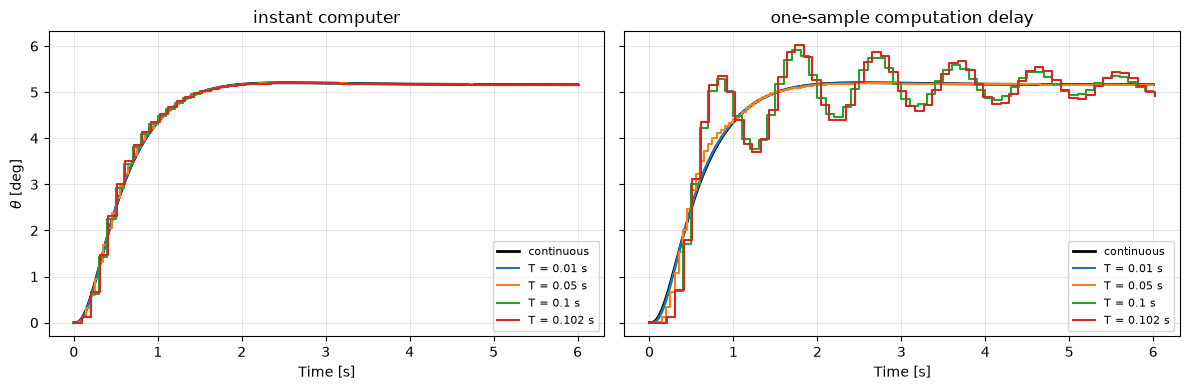

In [47]:
# Step responses (u2 = 5 deg) of the sampled loop against the continuous loop at the recommended gains
k1, k2 = K1_rec, K2_rec
Tmx_d = t_max(k1, k2, delay=True)
T_list = [0.01, 0.05, 0.1, round(0.9 * Tmx_d, 3)]
Tc = np.linspace(0, 6, 1200)
A_c, B_c = np.array(build_system(k1, k2)[0]), np.array(build_system(k1, k2)[1])
_, yc = signal.step(signal.StateSpace(A_c, B_c[:, [1]], np.array(C_PITCH), np.zeros((1, 1))), T=Tc)
size = np.radians(5)
fig, axs = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
print(f"gains ({k1:g}, {k2:g}); continuous: Mp = {100*(yc.max()/yc[-1]-1):.2f} %, ts = {settling_time(Tc, yc, yc[-1]):.2f} s")
print(f"{'T [s]':>7} {'delay':>6} | rho | Mp_th[%] ts_th[s]")
for ax, delay in zip(axs, (False, True)):
    ax.plot(Tc, np.degrees(size * yc), "k", lw=2, label="continuous")
    for T in T_list:
        t, th, _ = sampled_step(k1, k2, T, which=1, size=size, delay=delay)
        ax.step(t, np.degrees(th), where="post", label=f"T = {T:g} s")
        print(f"{T:7.3f} {str(delay):>6} | {spectral_radius(k1, k2, T, delay):.3f} | {100*(th.max()/th[-1]-1):8.2f} {settling_time(t, th, th[-1]):8.2f}")
    ax.set_title("instant computer" if not delay else "one-sample computation delay")
    ax.set_xlabel("Time [s]"); ax.grid(alpha=0.3); ax.legend(fontsize=8)
axs[0].set_ylabel(r"$\theta$ [deg]"); plt.tight_layout(); save_fig("fig_sampling"); plt.show()

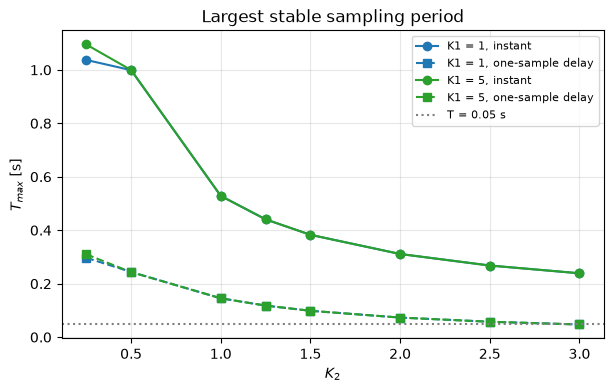

10-90 % rise time of theta at the recommended gains: 0.97 s
samples per rise time at T = 0.05 s: 19  (rule of thumb: 10-20 or more)
T = 0.05 s is 2.3x below T_max (worst case, one-sample delay)


In [ ]:
# T_max versus K2 (K1 = 1 and 5) and a rule for choosing T
K2_t = np.array([0.25, 0.5, 1.0, 1.25, 1.5, 2.0, 2.5, 3.0])
fig, ax = plt.subplots(figsize=(7, 4))
for k1_, col in ((1.0, "tab:blue"), (5.0, "tab:green")):
    ax.plot(K2_t, [t_max(k1_, k2_) for k2_ in K2_t], "o-", color=col, label=f"K1 = {k1_:g}, instant")
    ax.plot(K2_t, [t_max(k1_, k2_, delay=True) for k2_ in K2_t], "s--", color=col, label=f"K1 = {k1_:g}, one-sample delay")
ax.axhline(T_sample, color="gray", ls=":", label="T = 0.05 s"); ax.set_xlabel("$K_2$"); ax.set_ylabel("$T_{max}$ [s]")
ax.set_title("Largest stable sampling period"); ax.grid(alpha=0.3); ax.legend(fontsize=8)
save_fig("fig_tmax_vs_k2"); plt.show()

tr_idx = np.argmax(yc >= 0.9 * yc[-1])
tr = Tc[tr_idx] - Tc[np.argmax(yc >= 0.1 * yc[-1])]
print(f"10-90 % rise time of theta at the recommended gains: {tr:.2f} s")
print(f"samples per rise time at T = 0.05 s: {tr / T_sample:.0f}  (rule of thumb: 10-20 or more)")
print(f"T = 0.05 s is {Tmx_d / T_sample:.1f}x below T_max (worst case, one-sample delay)")

## F. Conclusions and open question
### F15. Time-varying mass: frozen-time illustration

Quasi-static illustration only (the report derives the new equations analytically). Assumptions: the mass falls by the factor
`1/rho`, inertia scales with mass, so `k_a, k_delta, mu, a_d, k_eps` grow by `rho` (`c_theta` is unchanged).
Case A keeps the gains fixed; case B schedules them, `K1/rho`, `K2/rho` (constant loop gain). `rho` values are illustrative.

gains K1 = 4.5, K2 = 1.3
  rho | A: fixed gains    max Re   T_max(delay) | B: scheduled gains  max Re   T_max(delay)
 1.00 |                    -1.625        0.114   |                      -1.625        0.114
 1.25 |                    -1.599        0.092   |                      -1.565        0.116
 1.50 |                    -1.604        0.077   |                      -1.509        0.118
 2.00 |                    -1.646        0.058   |                      -1.410        0.123


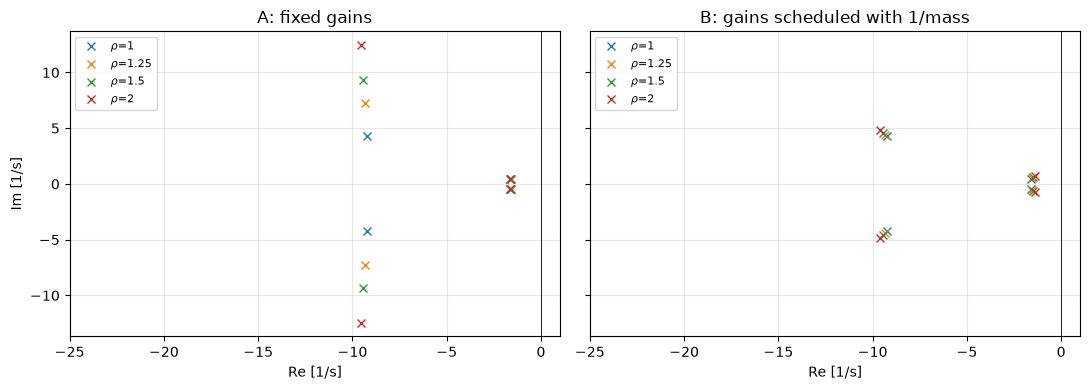

In [49]:
RHOS = [1.0, 1.25, 1.5, 2.0]
SCALED = ("k_a", "k_delta", "mu", "a_d", "k_eps")

def scaled_params(rho):
    return {k: PARAMS[k] * rho for k in SCALED}

def frozen_poles(K1_, K2_, rho):
    A_, *_ = build_system(K1_, K2_, **scaled_params(rho))
    return np.linalg.eigvals(np.array(A_))

def t_max_scaled(K1_, K2_, rho, delay=True):
    """T_max with the scaled plant (re-uses t_max through temporary parameters)."""
    global PARAMS
    saved = PARAMS
    try:
        PARAMS = {**PARAMS, **scaled_params(rho)}
        return t_max(K1_, K2_, delay=delay)
    finally:
        PARAMS = saved

print(f"gains K1 = {K1_rec:g}, K2 = {K2_rec:g}")
print(f"{'rho':>5} | A: fixed gains    max Re   T_max(delay) | B: scheduled gains  max Re   T_max(delay)")
fig, axs = plt.subplots(1, 2, figsize=(11, 4), sharex=True, sharey=True)
for rho in RHOS:
    pa = frozen_poles(K1_rec, K2_rec, rho)
    pb = frozen_poles(K1_rec / rho, K2_rec / rho, rho)
    ta = t_max_scaled(K1_rec, K2_rec, rho)
    tb = t_max_scaled(K1_rec / rho, K2_rec / rho, rho)
    print(f"{rho:5.2f} |                  {pa.real.max():+8.3f}   {ta:10.3f}   |                    {pb.real.max():+8.3f}   {tb:10.3f}")
    axs[0].plot(pa.real, pa.imag, "x", label=rf"$\rho$={rho:g}")
    axs[1].plot(pb.real, pb.imag, "x", label=rf"$\rho$={rho:g}")
for ax, t in zip(axs, ("A: fixed gains", "B: gains scheduled with 1/mass")):
    ax.set_title(t); ax.axvline(0, color="k", lw=0.6); ax.set_xlabel("Re [1/s]"); ax.grid(alpha=0.3); ax.legend(fontsize=8)
axs[0].set_ylabel("Im [1/s]"); axs[0].set_xlim(-25, 1)
plt.tight_layout(); save_fig("fig_f15_frozen_poles"); plt.show()

### F14. Summary of results (numbers quoted in the report)

In [50]:
# One place with every number the report quotes. Nominal = (K1, K2) = (1, 0.5); recommended = (K1_rec, K2_rec).
nom_m, rec_m = gain_metrics(1.0, 0.5), gain_metrics(K1_rec, K2_rec)
cm_nom, cm_rec = coupling_metrics(1.0, 0.5), coupling_metrics(K1_rec, K2_rec)
k2min_all = [k2_min(k) for k in np.linspace(0.5, 20, 40)]
Am_nom = np.array(build_system(1.0, 0.5)[0]); Am_rec = np.array(build_system(K1_rec, K2_rec)[0])
Tmx_nom, Tmx_rec = t_max(1.0, 0.5, delay=True), t_max(K1_rec, K2_rec, delay=True)

rows = [
 ("Poles nominal (1/s)",              ", ".join(f"{z:.3f}" for z in np.linalg.eigvals(Am_nom))),
 ("Poles recommended (1/s)",          ", ".join(f"{z:.3f}" for z in np.linalg.eigvals(Am_rec))),
 ("K2_min over K1 in [0.5, 20]",      f"{min(k2min_all):.3f} .. {max(k2min_all):.3f}"),
 ("Unstable pole with K2 = 0 (1/s)",  f"{r0['max_re']:+.4f}"),
 ("Coupling u2->a / u1->theta nominal (%)",     f"{nom_m['c21']:.1f} / {nom_m['c12']:.1f}"),
 ("Coupling u2->a / u1->theta recommended (%)", f"{rec_m['c21']:.1f} / {rec_m['c12']:.1f}"),
 ("Nominal: Mp, ts, ess, dmax",       f"{nom_m['Mp_th']:.1f} %, {nom_m['ts_th']:.2f} s, {nom_m['ess']:.2f} %, {nom_m['dmax']:.2f} deg"),
 ("Recommended: Mp, ts, ess, dmax",   f"{rec_m['Mp_th']:.2f} %, {rec_m['ts_th']:.2f} s, {rec_m['ess']:.2f} %, {rec_m['dmax']:.2f} deg"),
 ("Recommended point / zone",         f"({K1_rec:g}, {K2_rec:g}) / K1 [{K1_g[zc].min():g}, {K1_g[zc].max():g}], K2 [{K2_g[zr].min():g}, {K2_g[zr].max():g}]"),
 ("T_max with delay, nominal / recommended (s)", f"{Tmx_nom:.3f} / {Tmx_rec:.3f}"),
 ("T_max without delay, nominal / recommended (s)", f"{t_max(1.0, 0.5):.3f} / {t_max(K1_rec, K2_rec):.3f}"),
]
for k, v in rows:
    print(f"{k:50s} {v}")

Poles nominal (1/s)                                -17.264+0.000j, -2.092+0.000j, -1.066+1.199j, -1.066-1.199j
Poles recommended (1/s)                            -9.241+4.267j, -9.241-4.267j, -1.625+0.464j, -1.625-0.464j
K2_min over K1 in [0.5, 20]                        0.046 .. 0.085
Unstable pole with K2 = 0 (1/s)                    +0.5569
Coupling u2->a / u1->theta nominal (%)             176.9 / 20.6
Coupling u2->a / u1->theta recommended (%)         30.5 / 28.3
Nominal: Mp, ts, ess, dmax                         16.4 %, 3.64 s, 4.03 %, 2.01 deg
Recommended: Mp, ts, ess, dmax                     0.82 %, 1.62 s, 3.25 %, 4.49 deg
Recommended point / zone                           (4.5, 1.3) / K1 [4, 6.5], K2 [1.1, 1.45]
T_max with delay, nominal / recommended (s)        0.244 / 0.114
T_max without delay, nominal / recommended (s)     0.999 / 0.427
